# 第3回 A｜小球のシミュレーション
**曹研究室 B3基礎教育｜独立実行できる小球篇 v10**

「ドライブにコピー」で自分のNotebookを保存し、このNotebookを上から進めます。

**学ぶ順番：** 小球の力学 → Euler／RK4／解析解 → MuJoCoの小球 → 床と関節 → Terminal → 横向き運動・抵抗。

各例で予想し、自分でコードを書き、数値を根拠に回答します。AIに相談しても、採用した行の役割は自分で説明します。すべて必修です。授業・課外の配分は担当者の案内に従い、途中の到達位置を残します。

**課題は翌週のPPT発表で説明します。** Notebookの回答・自作コード・図を発表の準備に使います。ZIPの提出は不要です。

ロボットは別の [B：2リンクロボット篇](https://colab.research.google.com/github/jasonsosen/b3-foundations-2026/blob/main/materials/03/two_link_robot.ipynb) です。Aの変数・ファイルをBへ渡す必要はありません。PDFは従来版v6、実習手順は各Notebookを使います。

## 0｜なぜシミュレータを学ぶのか
シミュレーションでは、モデルと計算を使って「条件を変えるとどうなるか」を調べます。
同じ初期条件から繰り返せるので、制御方法や設計案を比較しやすくなります。

|研究の場面|シミュレーションで試すこと|実物で確認すること|
|---|---|---|
|ロボットのSim-to-Real|歩行・把持などの制御を試し、質量・摩擦・遅れを変えて調べる|センサやモータの違い、実機の動作|
|人体の運動・リハビリテーション|骨・関節・筋のモデルを使い、動作や関節負荷を推定する|計測データとの一致、個人差、装置条件|
|機械の設計|リンクの長さ、可動域、接触、入力の大きさを比較する|寸法、強度、摩擦などの実測|

**Sim-to-Real** は、仮想環境で調べた制御や学習結果を実機へ移す考え方です。モデルの誤差があるため、移せば必ず動くわけではありません。
例としてTanら（RSS 2018）は、シミュレーションで学習した四脚歩行を実機で評価し、モータ・遅れのモデル化や物理条件の変動を扱いました。[論文](https://www.roboticsproceedings.org/rss14/p10.pdf)

人体では [OpenSim](https://opensim.stanford.edu/) やMuJoCoを用いる [MyoSuite](https://myosuite.readthedocs.io/en/latest/) などがあります。
ここで作る2リンクは仕組みを学ぶ簡略モデルです。筋力・痛み・安全性を測定した結果にはなりません。

**ひとこと記入：** 自分の興味がある機械や人体運動で、仮想実験をしてみたい問いは何ですか？  
（ここに記入）

### 実際のシミュレーション画面

これは公式プロジェクトのモデル画像です。このNotebookが計算した結果とは区別します。


**ロボットアーム**

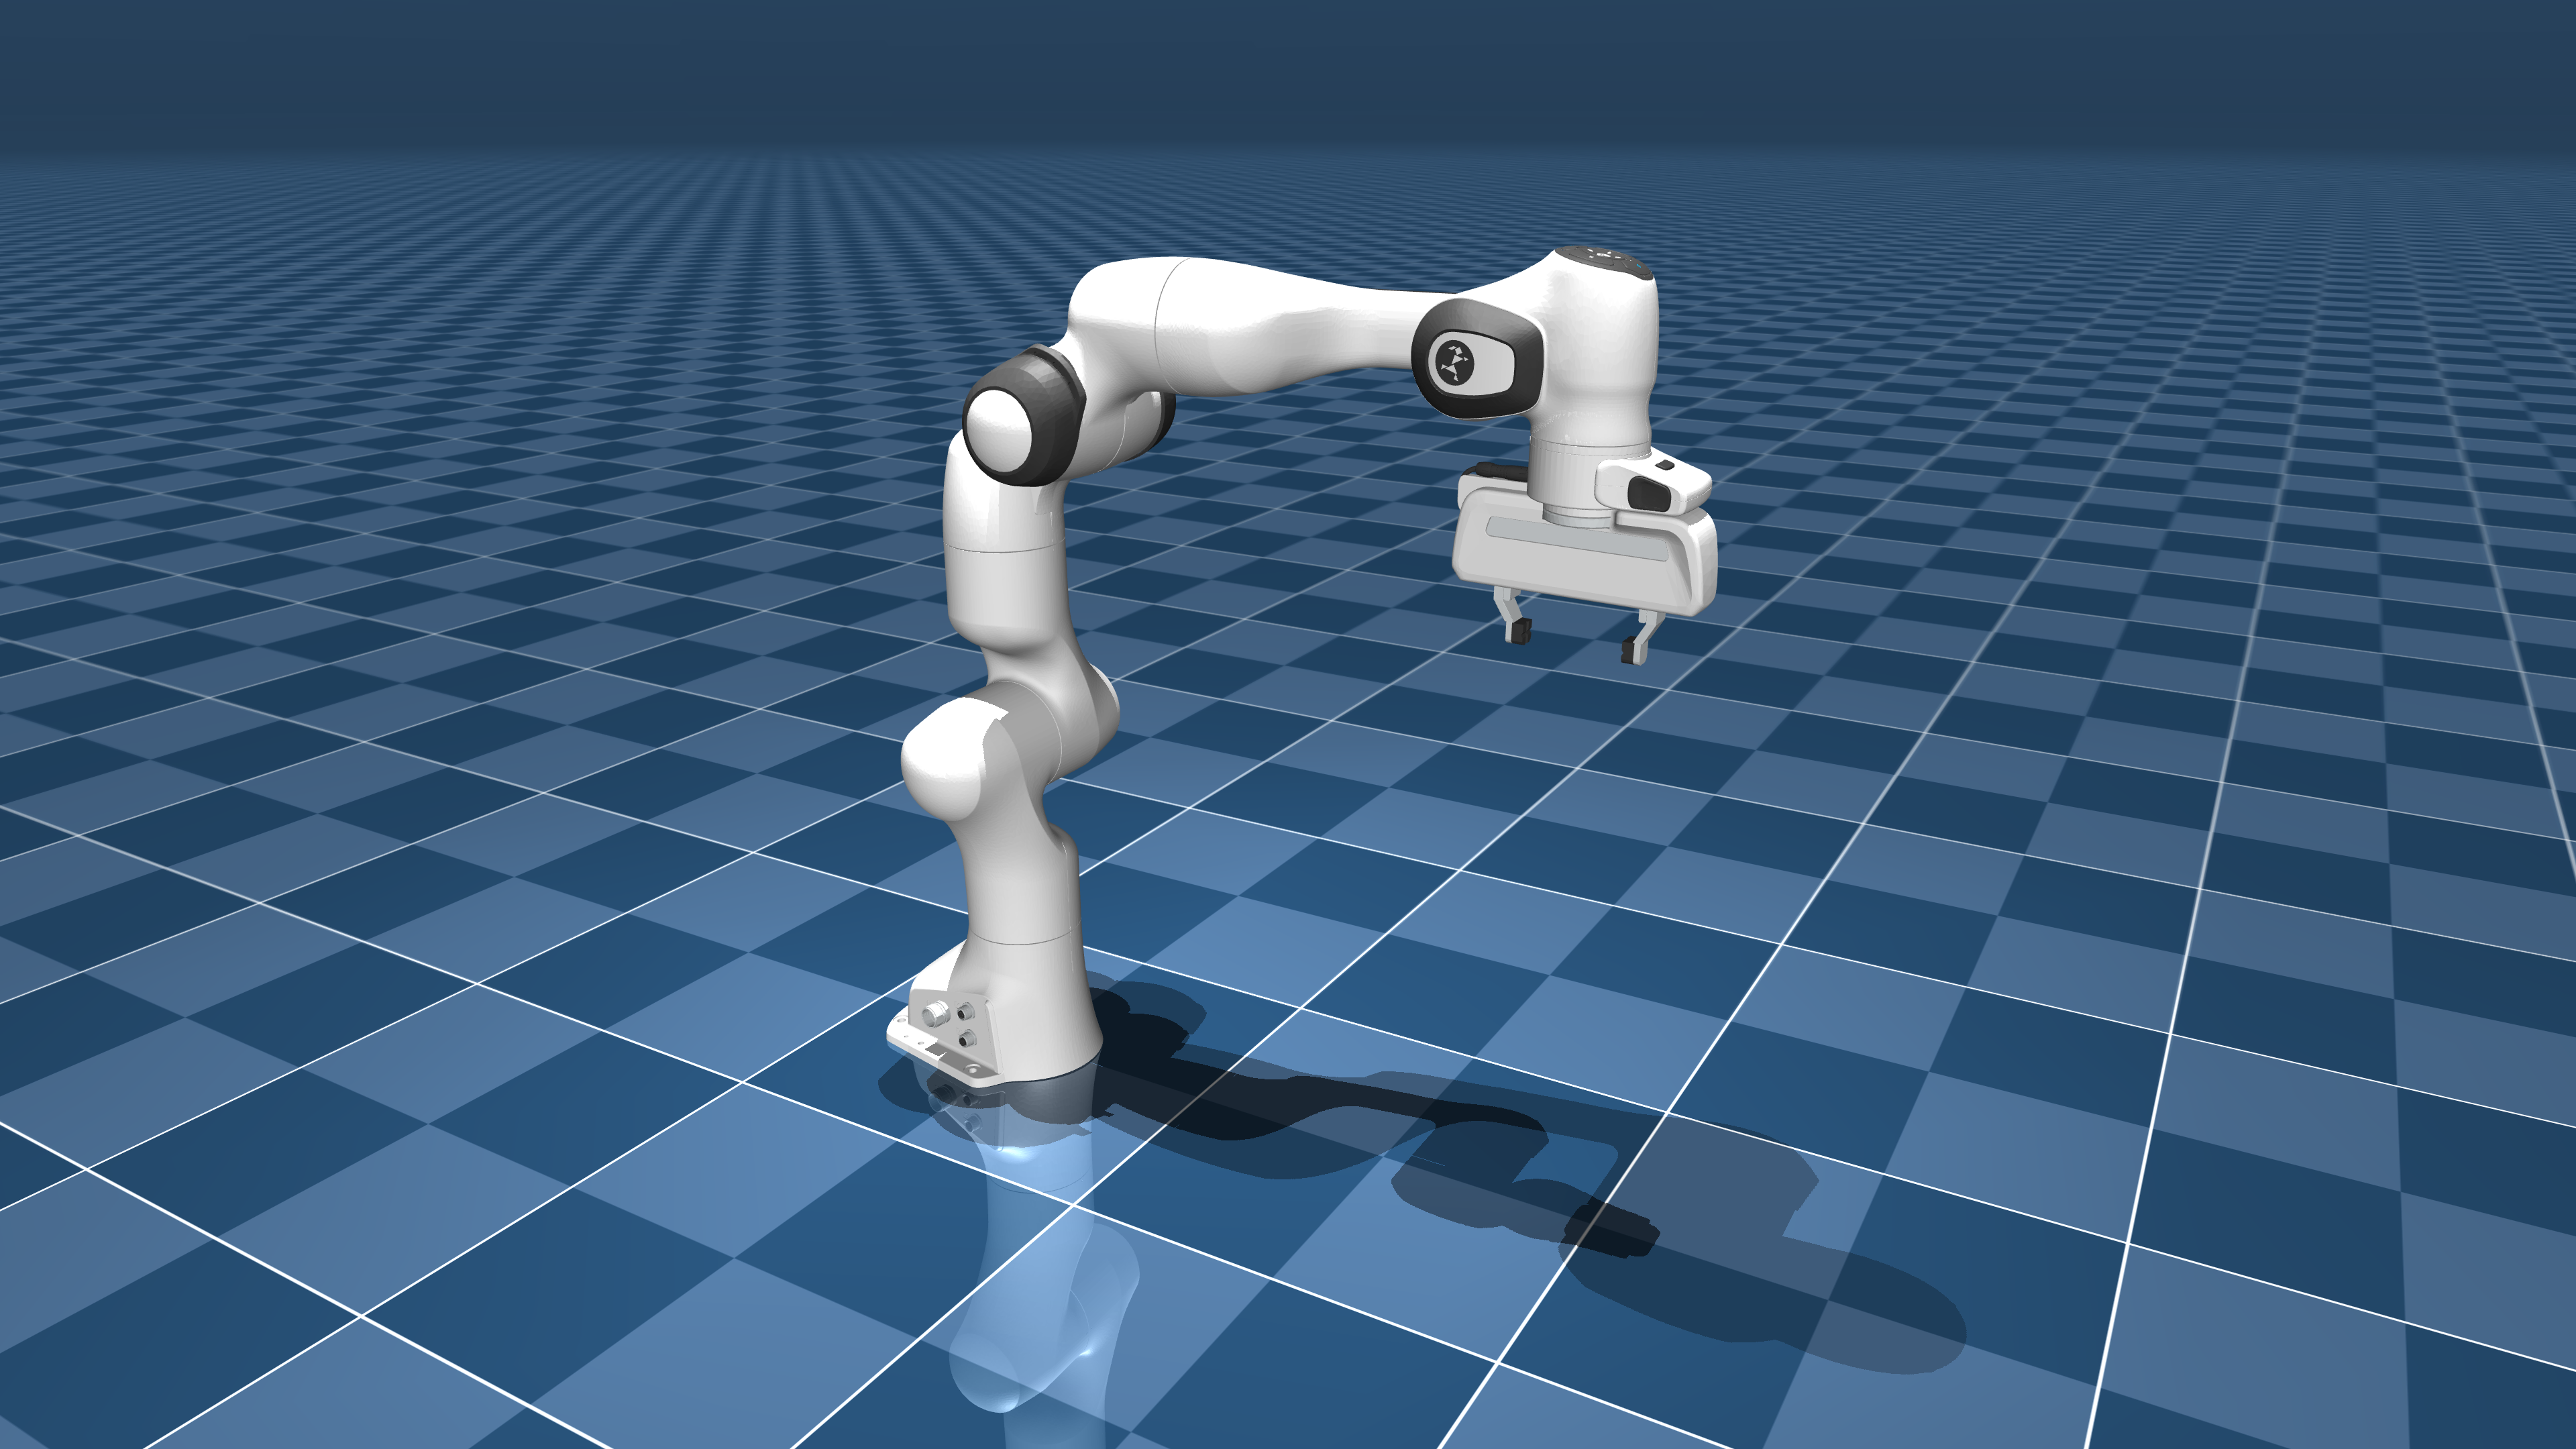

Franka Emika Panda。関節とリンクを含む仮想モデル。 [画像の出典](https://github.com/google-deepmind/mujoco_menagerie/tree/main/franka_emika_panda)


**四足ロボット**

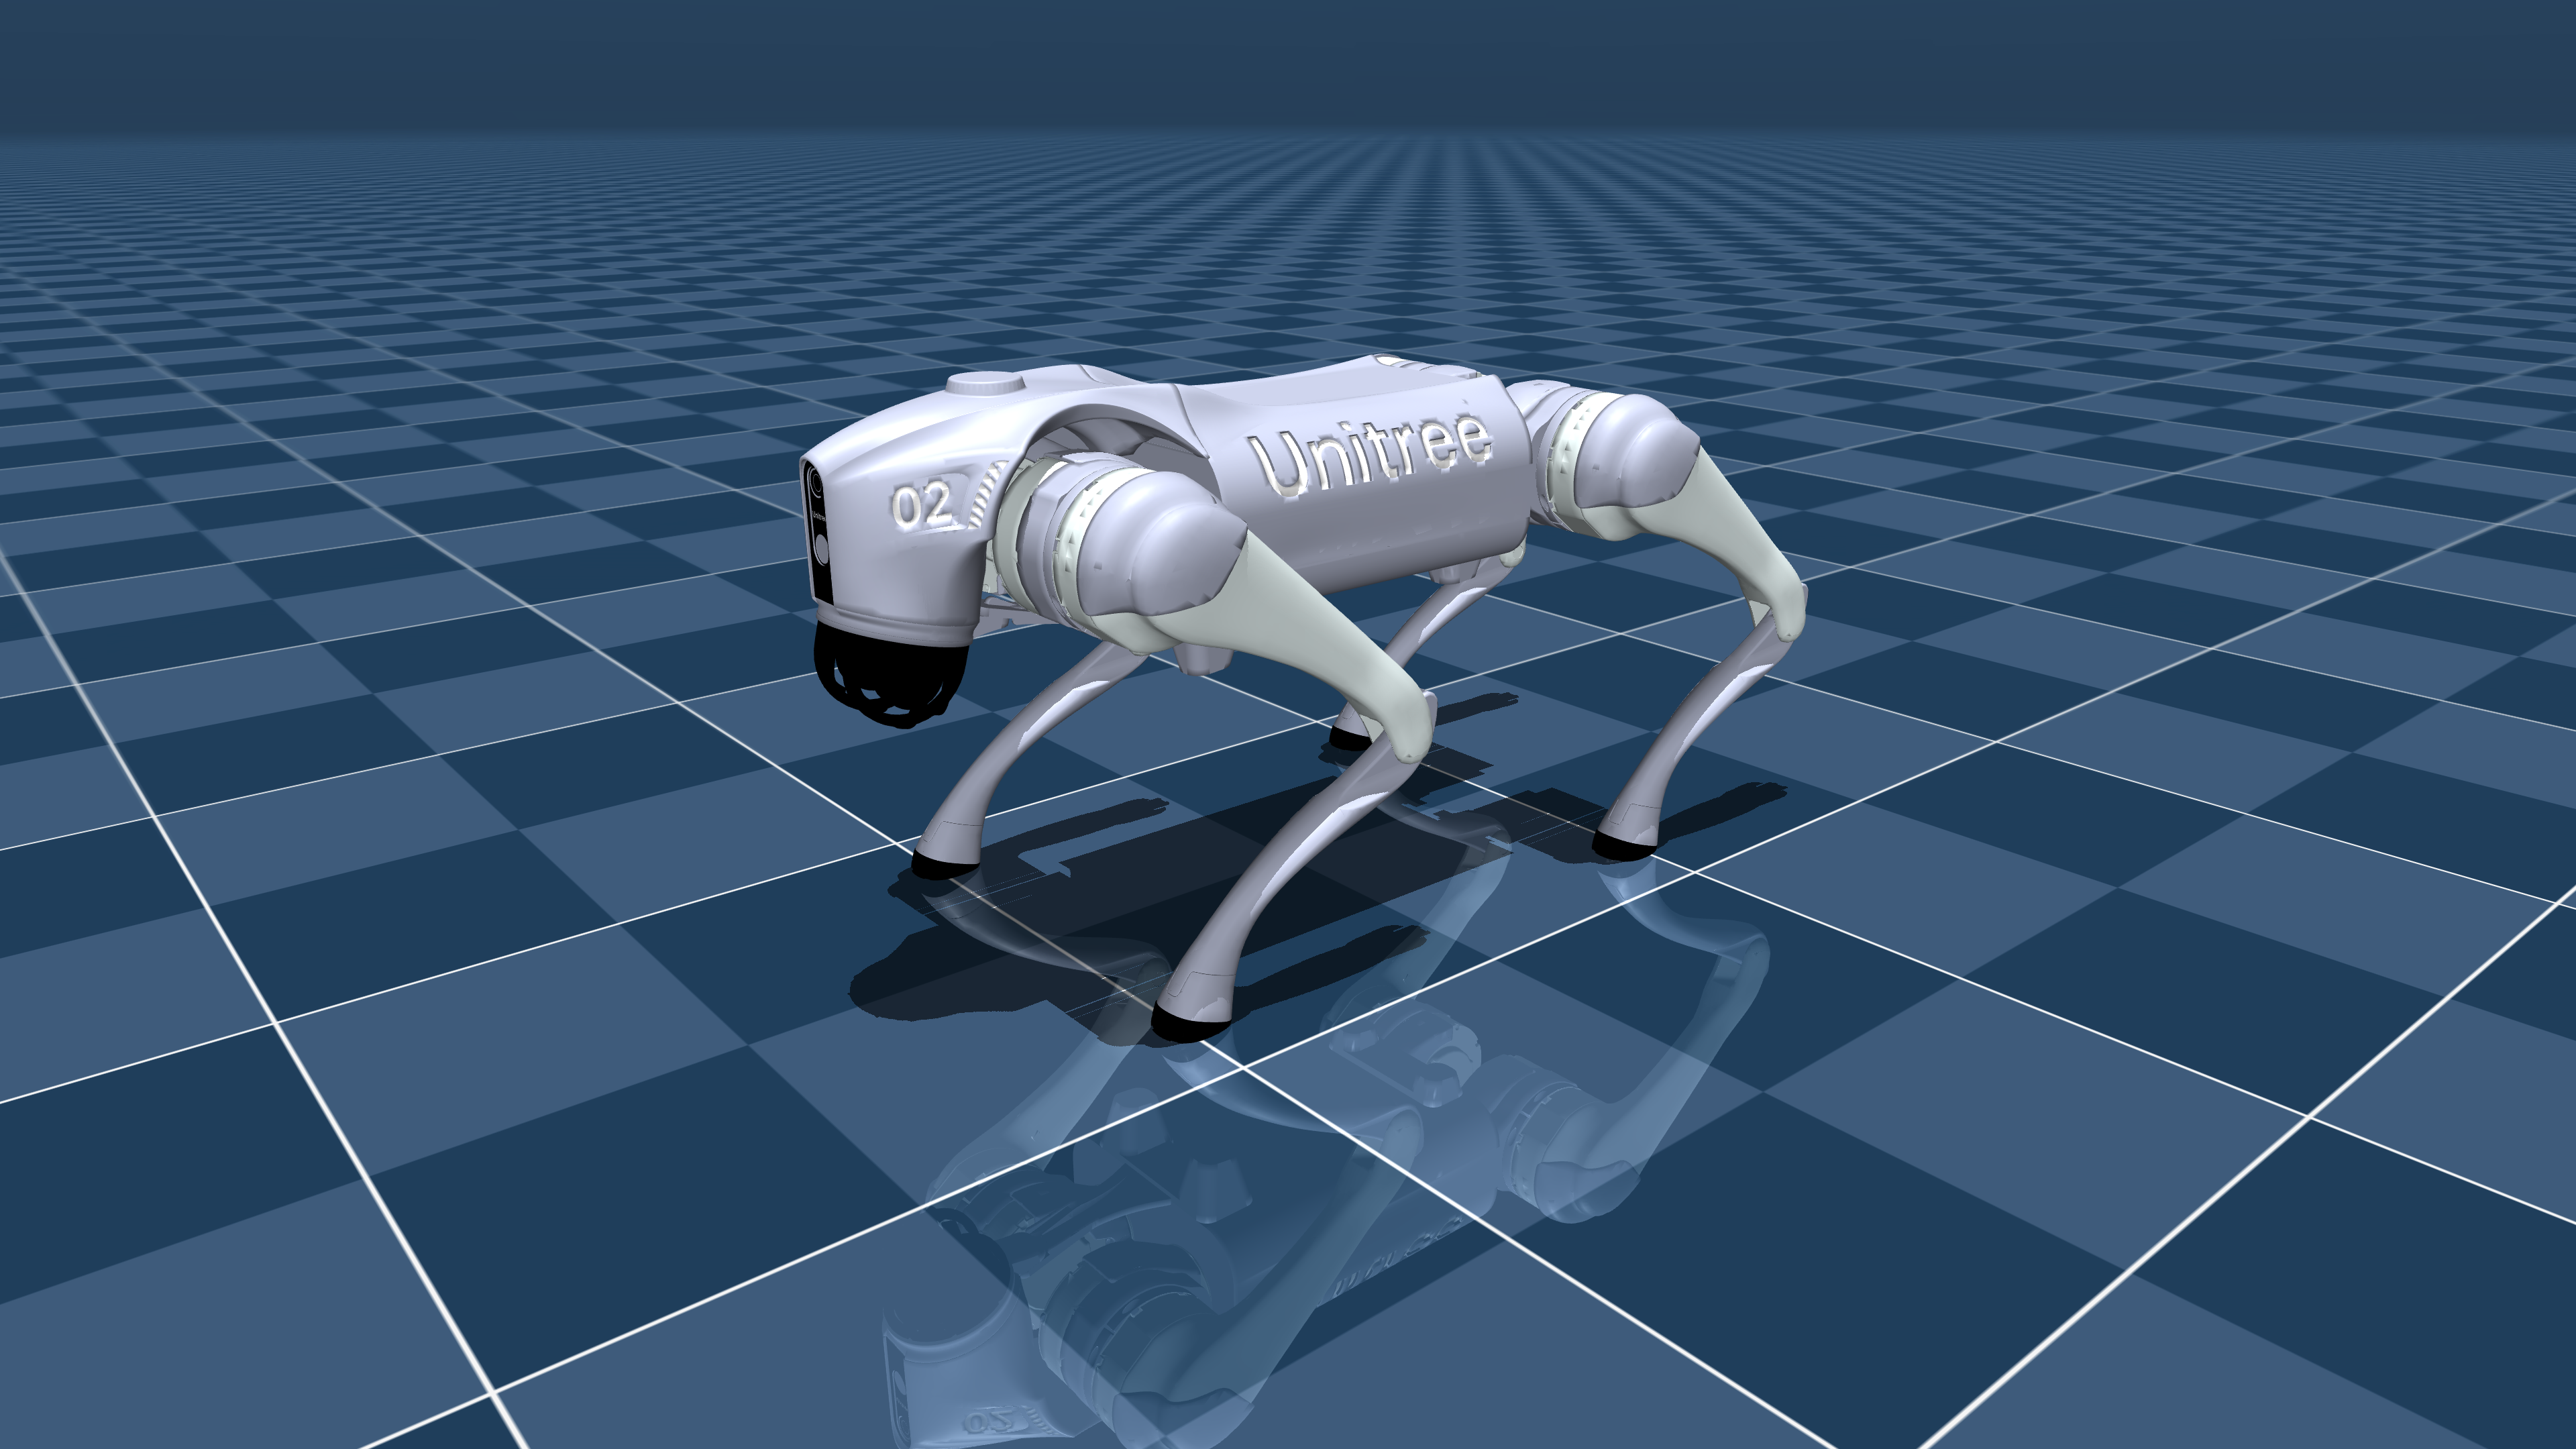

Unitree Go2の仮想モデル。歩行の制御を試す場面を考えます。上のTanらのMinitaurとは別のロボットです。 [画像の出典](https://github.com/google-deepmind/mujoco_menagerie/tree/main/unitree_go2)


**人体の筋骨格モデル**

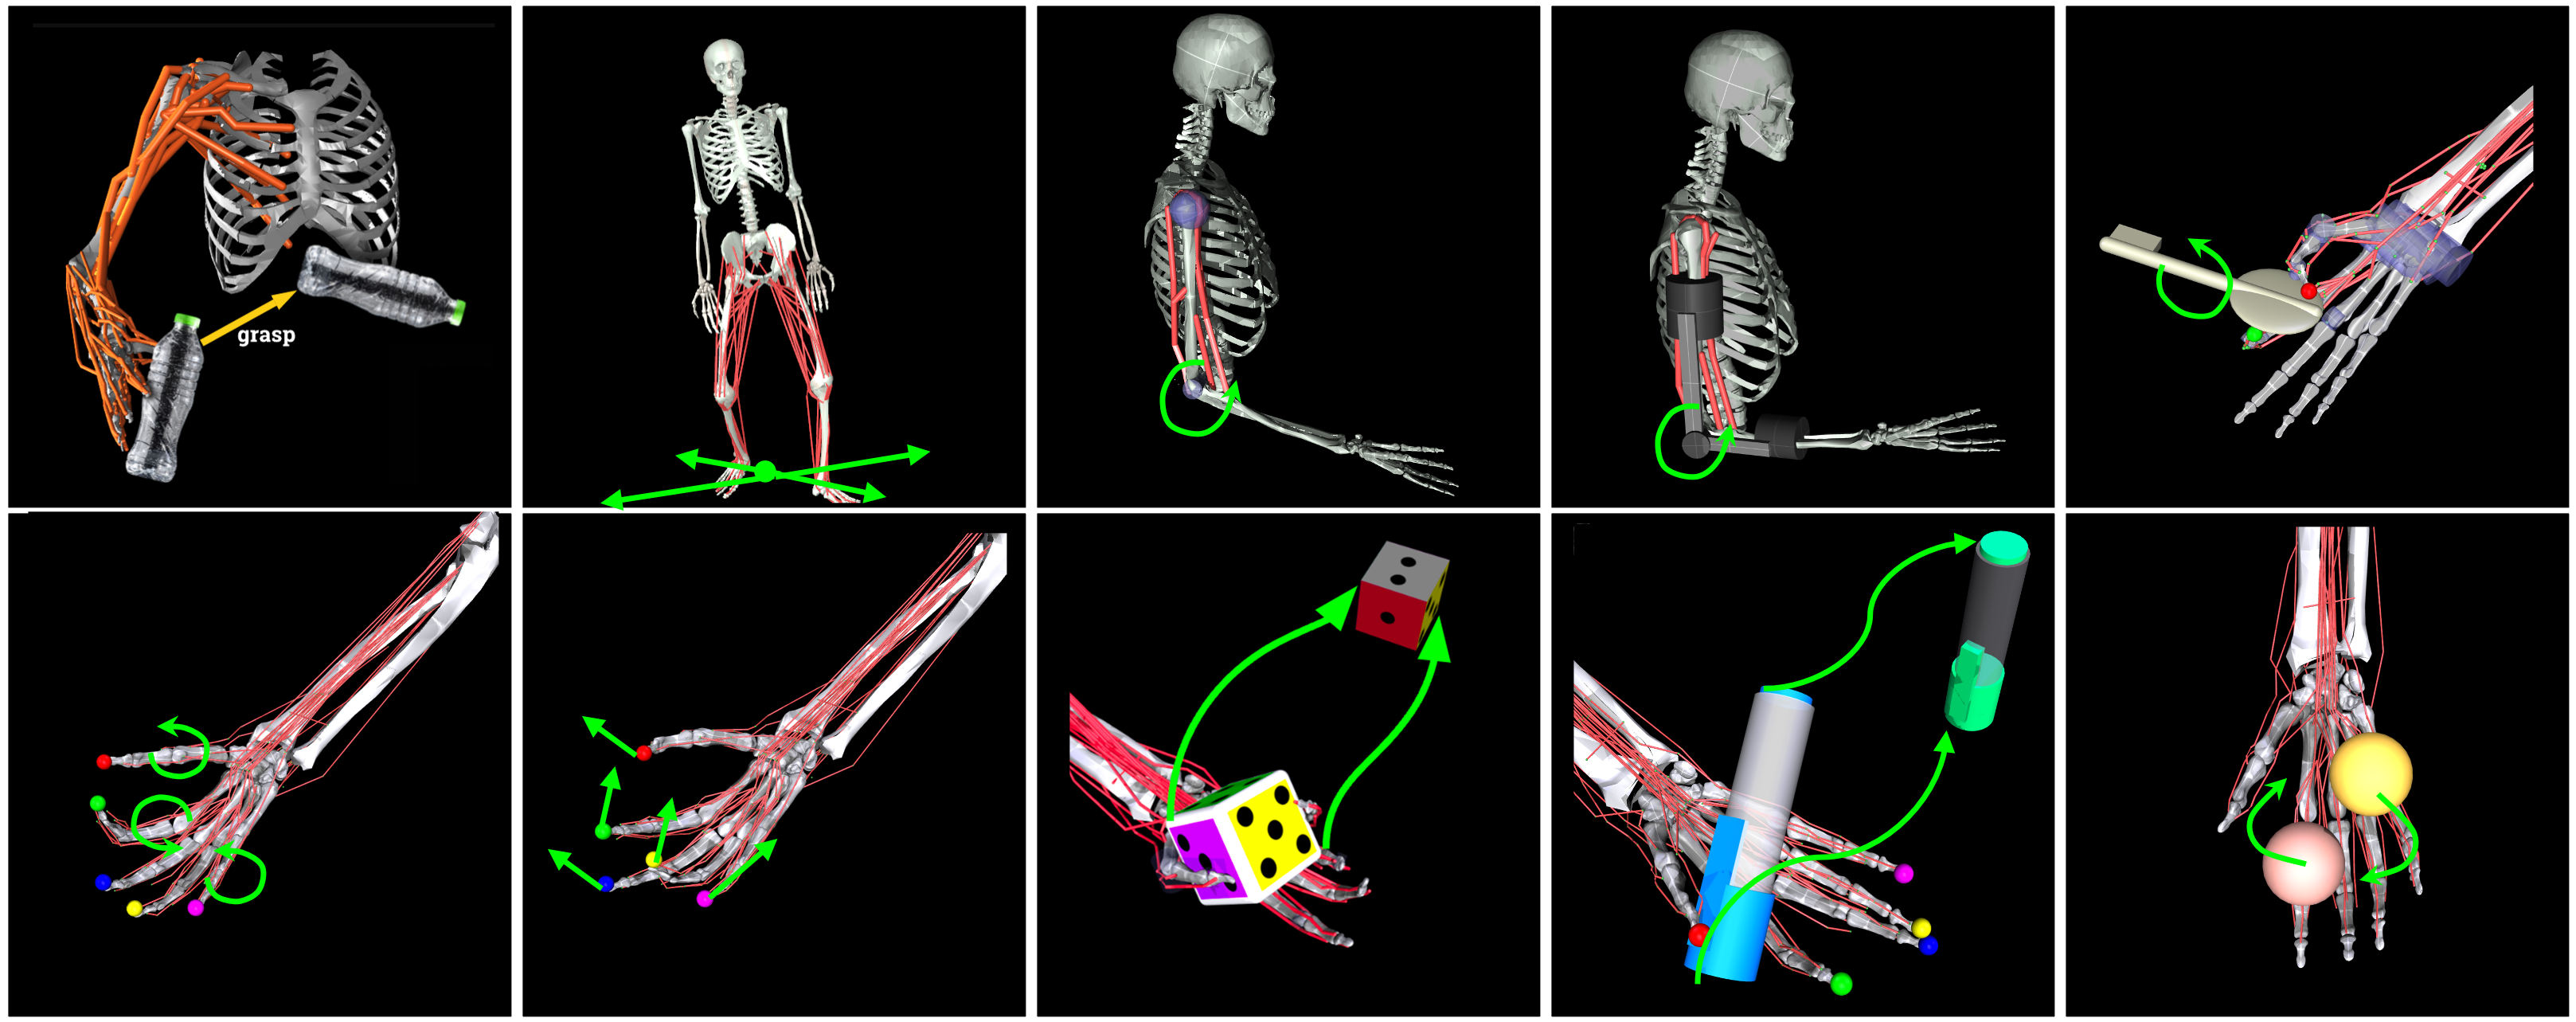

MyoSuiteの腕・脚・手指の課題例。骨だけでなく、筋・関節・接触をモデル化します。 [画像の出典](https://github.com/MyoHub/myosuite)

**画像を見て確認：** 動く部分、地面や物体との接触、与える入力を一つずつ挙げてください。

（ここに記入）

## 準備｜表示と保存の道具
次のセルはライブラリと描画関数を準備します。一度実行して閉じて構いません。
`print(...)` は値を表示、`display(...)` は表や動画を表示します。計算の中身は次の節から読みます。

In [1]:
#@title 準備と表示用コード（実行してから折りたたんでよい）
import sys, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle
from IPython.display import display, HTML
get_ipython().run_line_magic('matplotlib', 'inline')
WORK = Path.cwd() / 'b3_lesson03A_ball'
WORK.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 12})
mission_status = {}

def ball_animation(log, name, target=None):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    xmax = max(2.25, float(log.x_m.max()) + 0.2)
    ax.set(xlim=(-0.2, xmax), ylim=(-0.12, max(1.25, float(log.z_m.max())+0.1)),
           xlabel='Horizontal position x [m]', ylabel='Height z [m]')
    ax.axhline(0, color='#17323b', lw=2)
    if target is not None:
        ax.plot(target, [0, 0], lw=9, color='#c9633d', label='Target interval')
        ax.legend(loc='upper right')
    trail, = ax.plot([], [], color='#247c7a', lw=1)
    dot, = ax.plot([], [], 'o', color='#247c7a', ms=13)
    label = ax.text(0.02, 0.94, '', transform=ax.transAxes)
    fig.tight_layout()
    def update(i):
        dot.set_data([log.x_m.iloc[i]], [log.z_m.iloc[i]])
        trail.set_data(log.x_m.iloc[:i+1], log.z_m.iloc[:i+1])
        label.set_text(f'Simulation time: {log.time_s.iloc[i]:.3f} s')
        return dot, trail, label
    animation = FuncAnimation(fig, update, frames=len(log), interval=65, blit=True)
    content = animation.to_jshtml(default_mode='once')
    update(len(log)-1); fig.tight_layout()
    fig.savefig(WORK / f'{name}.png', dpi=130)
    plt.close(fig)
    (WORK / f'{name}.html').write_text(content, encoding='utf-8')
    return HTML(content)

def check_mission(name, passed, measured, target, settings):
    mission_status[name] = bool(passed)
    status = '達成' if passed else 'もう一度試そう'
    record = {'mission': name, 'passed': bool(passed), 'measured': measured,
              'target': target, 'settings': settings}
    with (WORK / 'trial_history.jsonl').open('a', encoding='utf-8') as f:
        f.write(json.dumps(record, ensure_ascii=False) + '\n')
    print(f'{name}：{status}')
    print('今回の結果：', measured)
    print('目標：', target)
    print('変更条件と結果をtrial_history.jsonlへ記録しました。')

print('準備できました。第1節から一歩ずつ進めましょう。')
print('作業フォルダ：', WORK)

準備できました。第1節から一歩ずつ進めましょう。
作業フォルダ： /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/ball-student/b3_lesson03A_ball


## 1｜動力学シミュレーションは何を計算する？
机の上から球を静かに放す場面を考えます。球は重力を受け、速度が変わり、位置が変わります。

**物体・環境のモデル＋初期状態 → 力と加速度 → 次の速度・位置 → 同じ計算を繰り返す**

これが今回の動力学シミュレーションです。動画は、計算した結果を見える形にします。
画面の位置を順番に指定するだけでも動画は作れます。その場合、力から運動を予測したかどうかは別に確認が必要です。

### 今回のモデルと記号
まず床に接触する前だけを扱います。空気抵抗なし・重力一定・上下1方向です。

|記号 / Python|意味|単位|
|---|---|---|
|$z$ / `height`|高さ。上向きを正、地面を0とする|m|
|$v$ / `velocity`|上向きの速度。下向きなら負|m/s|
|$a$ / `acceleration`|速度の変化の速さ|m/s²|
|$g$ / `g`|重力加速度の大きさ（正の数）|m/s²|
|$\Delta t$ / `dt`|1回に進める仮想時間|s|

**質点モデル：** 最初は球の大きさを無視します。MuJoCoでは半径を持つ剛体にします。

### 1.1｜まず現在の高さだけ読む
`=` は右の値を左の変数へ入れる命令です。次の2行は位置を決めて表示するだけです。

In [2]:
height = 1.0  # 地面からの高さ [m]
print("height [m] =", height)

height [m] = 1.0


### 1.2｜位置と速度は別の量
球を静かに放す直前は、高さが1 m、速度が0 m/sです。速度0でも高さ0とは限りません。

In [3]:
velocity = 0.0  # 上向きの速度 [m/s]
print("velocity [m/s] =", velocity)

velocity [m/s] = 0.0


### 1.3｜力から加速度を求める
ニュートンの運動方程式は $ma=F$。上向きが正なので重力は $F=-mg$ です。
$$a=\frac{F}{m}=\frac{-mg}{m}=-g.$$
重力だけなら、このモデルの加速度は質量によらず同じです。

In [4]:
mass = 1.0  # kg
g = 9.81  # 重力加速度の大きさ [m/s²]
force = -mass * g
acceleration = force / mass
print("force [N], acceleration [m/s²] =", force, acceleration)

force [N], acceleration [m/s²] = -9.81 -9.81


## 2｜一小刻みだけ計算する：顕式Euler法
連続時間の式を、変化の速さとして読みます。
$$\frac{dz}{dt}=v,\qquad \frac{dv}{dt}=-g.$$
位置の変化率は速度、速度の変化率は加速度です。
短い時間なら「変化量 ≈ いまの変化率 × 時間」と近似できます。これを一歩ずつ使います。

### 2.1｜同じ出発点を用意する
この節をやり直すときは、次の初期化セルから実行してください。

In [5]:
height, velocity = 1.0, 0.0
dt = 0.1  # 1回に0.1秒進める
time_s = 0.0

### 2.2｜次の高さを試算する
$$z_{n+1}=z_n+v_n\Delta t.$$
`next_height` は計算結果を一時的に入れる名前です。まだ `height` は書き換えません。

In [6]:
next_height = height + velocity * dt
print("next_height [m] =", next_height)

next_height [m] = 1.0


### 2.3｜次の速度を試算する
$$v_{n+1}=v_n-g\Delta t.$$
こちらも開始時の `velocity` を使います。加速度が負なので速度は下向きになります。

In [7]:
next_velocity = velocity - g * dt
print("next_velocity [m/s] =", next_velocity)

next_velocity [m/s] = -0.9810000000000001


### 2.4｜試算した値を現在の状態へ移す
`height, velocity = ...` は二つの値をまとめて更新します。時間も一歩進めます。
計算後に、下の問い1へ進みます。

In [8]:
height, velocity = next_height, next_velocity
time_s = time_s + dt
print("time [s], height [m], velocity [m/s] =", time_s, height, velocity)

time [s], height [m], velocity [m/s] = 0.1 1.0 -0.9810000000000001


### 問い 1
最初の0.1秒で、顕式Eulerの高さは1 mのまま、速度は負になりました。式のどの値がその理由を説明しますか。実際の球も0.1秒間、高さが変わらないでしょうか。

**自分の説明：**（記入）  
**根拠にしたコード・数値：**（記入）

### 2.5｜一つにつなぐと、シミュレーションになる
ここまでの行をまとめます。新しい物理式はありません。**初期化 → 一歩を繰り返す → 記録**を探してください。

|部分|役割|
|---|---|
|最初の4行|重力、初期状態、刻み、記録の準備|
|`for`の中|同じEulerの一歩を8回実行|
|`rows.append`|更新後の時刻・高さ・速度を保存|
|最後の2行|記録を表にして確認|

`next_height`と`next_velocity`を計算してから更新します。初期状態も記録するため、8回の計算で表は9行になります。まず0.05秒で実行します。

In [9]:
g = 9.81
height, velocity = 1.0, 0.0
dt, steps = 0.05, 8
rows = [[0.0, height, velocity]]
for i in range(steps):
    next_height = height + velocity * dt
    next_velocity = velocity - g * dt
    height, velocity = next_height, next_velocity
    rows.append([(i + 1) * dt, height, velocity])
euler_log = pd.DataFrame(rows, columns=["time_s", "height_m", "velocity_mps"])
display(euler_log.head(3), euler_log.tail(2))

,time_s,height_m,velocity_mps
0,0.00,1.000000,0.0000
1,0.05,1.000000,-0.4905
2,0.10,0.975475,-0.9810


,time_s,height_m,velocity_mps
7,0.35,0.484975,-3.4335
8,0.40,0.313300,-3.9240


**小課題：** 刻みを0.01秒にして、**同じ0.40秒まで**計算してください。`steps`も自分で直します。予想した計算回数：（記入）。
その後、元の `dt=0.05, steps=8` に戻してもう一度実行します。次の動画は計算済みの表を描くだけで、力学計算を追加しません。

In [10]:
animation_log = euler_log.rename(columns={"height_m": "z_m"}).assign(x_m=0.0)
display(ball_animation(animation_log, "euler_ball"))

## 3｜解析解を基準にする
重力一定、空気抵抗なし、床に触れる前の理想モデルでは、次の解析解が得られます。
$$z(t)=z_0+v_0t-\frac12gt^2,\qquad v(t)=v_0-gt.$$
同じモデルの厳密な解なので、計算の答え合わせに使えます。実測値ではありません。

|式|Pythonの対応|
|---|---|
|$z_0+v_0t-\tfrac12gt^2$|`z0 + v0 * t - 0.5 * g * t**2`|
|$v_0-gt$|`v0 - g * t`|

次の0.40秒の値を、Eulerの表の最後の高さと比べてください。

In [11]:
z0, v0, final_time = 1.0, 0.0, 0.4
exact_height = z0 + v0 * final_time - 0.5 * g * final_time**2
print("解析解 [m] =", exact_height)
print("Euler誤差 [m] =", abs(euler_log.height_m.iloc[-1] - exact_height))

解析解 [m] = 0.21519999999999984
Euler誤差 [m] = 0.09809999999999997


## 4｜Runge–Kutta法：式を見て自分で実装する
### 4.1｜二つの数をまとめ、同じプログラムを使う
$\boldsymbol{s}=[z,v]^T$ を `state`、変化率 $\boldsymbol{f}(\boldsymbol{s})=[v,-g]^T$ を `ball_rate` とします。
`state[0]` は高さ、`state[1]` は速度です。関数の出力は、それぞれの**変化の速さ**です。
関数も引数として渡せるので、`rate(state)` は「渡された変化率の関数を呼ぶ」という意味です。この課題は変化率が状態だけで決まる場合を扱います。`state`は1次元の浮動小数点配列で、同じ形の新しい配列を返します。

顕式Eulerの2行は、配列では $\boldsymbol{s}_{n+1}=\boldsymbol{s}_n+\Delta t\boldsymbol{f}(\boldsymbol{s}_n)$ の1行にまとまります。

In [12]:
def ball_rate(state):
    return np.array([state[1], -g])

def euler_step(rate, state, dt):
    return state + dt * rate(state)

print(euler_step(ball_rate, np.array([1.0, 0.0]), 0.1))

[ 1.    -0.981]


### 4.2｜RK4の公式と変数の対応
Eulerは起点の変化率を使い、RK4（4次のルンゲ・クッタ法）は途中も含めて4回試算します。係数の導出は今回扱いません。

$$\begin{aligned}
\boldsymbol{k}_1&=\boldsymbol{f}(\boldsymbol{s}_n),\\
\boldsymbol{k}_2&=\boldsymbol{f}(\boldsymbol{s}_n+\tfrac{\Delta t}{2}\boldsymbol{k}_1),\\
\boldsymbol{k}_3&=\boldsymbol{f}(\boldsymbol{s}_n+\tfrac{\Delta t}{2}\boldsymbol{k}_2),\\
\boldsymbol{k}_4&=\boldsymbol{f}(\boldsymbol{s}_n+\Delta t\boldsymbol{k}_3),\\
\boldsymbol{s}_{n+1}&=\boldsymbol{s}_n+\tfrac{\Delta t}{6}(\boldsymbol{k}_1+2\boldsymbol{k}_2+2\boldsymbol{k}_3+\boldsymbol{k}_4).
\end{aligned}$$

|数式の記号|コードで使う名前|意味|
|---|---|---|
|$\boldsymbol{s}_n$|`state`|一歩の開始時の状態。途中で書き換えない|
|$\Delta t$|`dt`|一歩の時間|
|$\boldsymbol{f}(\cdot)$|`rate(...)`|仮の状態から変化率を計算|
|$\boldsymbol{k}_1,\ldots,\boldsymbol{k}_4$|`k1`〜`k4`|4回の変化率。位置そのものではない|
|$\boldsymbol{s}_{n+1}$|`return`の右側|次の状態を返す|

**プログラミング課題：下の4個の `None` を式に置き換えてください。** `k1`だけ例を示します。`k2`と`k3`は同じ開始状態から半歩を試算します。4回試算しても進む時間は1個の `dt` です。

まず自分で5分考えます。AIには最初から完成コードを頼まず、「この式の記号がコードのどれに対応するか」「エラーの理由」のように質問し、採用した変更を説明してください。

In [13]:
def rk4_step(rate, state, dt):
    k1 = rate(state)  # 第1式の実装例
    k2 = None  # TODO: 第2式
    k3 = None  # TODO: 第3式
    k4 = None  # TODO: 第4式
    return None  # TODO: 最後の式で次の状態を返す

### 4.3｜確認 → 同じループで比較
下の確認ツールは未完成・式の間違い・配列の書き換えを調べます。**解答は補いません。** 失敗したら関数のセルを直して再実行し、確認と比較のセルも実行し直します。

重力一定の落球だけでは、違う積分法でも偶然同じ値になる場合があります。確認ツールは別の変化率でも式の実装を調べます。これは物理課題の追加ではなく、プログラムの動作確認です。

In [14]:
#@title RK4の確認ツール（解答は自動補完しません）
def check_rk4(step, verbose=True):
    def finish(status, message):
        if verbose:
            print(status + "：" + message)
        return status == "PASS"
    try:
        state = np.array([1.0, 0.0]); before = state.copy()
        trial = step(ball_rate, state, 0.1)
        if trial is None:
            return finish("未完成", "rk4_stepの4か所を補完してください。")
        if not np.array_equal(state, before):
            return finish("再確認", "入力stateを書き換えています。各段階で元のstateを保ちます。")
        if np.asarray(trial).shape != (2,) or not np.isfinite(trial).all():
            return finish("再確認", "高さ・速度の有限な2成分を返してください。")
        if not np.allclose(trial, [0.95095, -0.981], rtol=0, atol=1e-11):
            return finish("再確認", "落球の一歩が合いません。dt、符号、最後の重みを見直します。")
        calls = []
        def probe(s):
            calls.append(np.array(s).copy())
            return np.array([s[0]**2 + s[1], -s[0] + 0.3*s[1]**2])
        start = np.array([0.4, -0.2]); initial = start.copy(); h = 0.07
        result = np.asarray(step(probe, start, h))
        if len(calls) != 4:
            return finish("再確認", "rateを4回呼ぶRK4になっているか確認します。")
        rates = [np.array([s[0]**2+s[1], -s[0]+0.3*s[1]**2]) for s in calls]
        expected_inputs = [initial, initial+h*rates[0]/2, initial+h*rates[1]/2, initial+h*rates[2]]
        if not np.array_equal(start, initial) or not np.allclose(calls, expected_inputs, rtol=0, atol=1e-12):
            return finish("再確認", "k2〜k4の試算位置が式と違います。起点と係数を確認します。")
        expected = initial + h*(rates[0]+2*rates[1]+2*rates[2]+rates[3])/6
        if result.shape != (2,) or not np.allclose(result, expected, rtol=0, atol=1e-12):
            return finish("再確認", "最後の加重平均の係数とdtを確認します。")
        return finish("PASS", "実装確認を通過しました。次に比較図を見て問い2に答えます。")
    except Exception as exc:
        return finish("再確認", type(exc).__name__ + ": " + str(exc) + " — 関数セルを修正・再実行してください。")

In [15]:
rk4_ready = check_rk4(rk4_step)

未完成：rk4_stepの4か所を補完してください。


**共通の繰り返し：** EulerとRK4で変えるのは `step_function` だけです。`simulate(euler_step)` はEulerの一歩を、`simulate(rk4_step)` は自分で書いたRK4の一歩を繰り返します。初期値・刻み・終了時刻はそろえます。

In [16]:
def simulate(step_function, dt=0.05, steps=8):
    state = np.array([1.0, 0.0])
    rows = [[0.0, *state]]
    for i in range(steps):
        state = step_function(ball_rate, state, dt)
        rows.append([(i + 1) * dt, *state])
    return pd.DataFrame(rows, columns=["time_s", "height_m", "velocity_mps"])

In [17]:
#@title 比較図と誤差表を表示する道具（計算は上のsimulateを使用）
def compare_methods(step):
    logs = {}; table = []
    for dt in [0.05, 0.01]:
        steps = round(0.4 / dt)
        for name, method in [("Euler", euler_step), ("RK4", step)]:
            log = simulate(method, dt, steps)
            exact = 1.0 - 0.5*g*log.time_s**2
            log["error_m"] = abs(log.height_m - exact)
            logs[(name, dt)] = log
            table.append([name, dt, steps, log.height_m.iloc[-1], log.error_m.iloc[-1]])
    table.append(["Analytical", np.nan, 0, 1.0-0.5*g*0.4**2, 0.0])
    comparison = pd.DataFrame(table, columns=["method", "dt_s", "steps", "height_m_at_0.4s", "absolute_error_m"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    t = logs[("Euler", 0.05)].time_s
    axes[0].plot(t, 1.0-0.5*g*t**2, color="black", label="Analytical")
    for name, style in [("Euler", "o--"), ("RK4", "x:")]:
        log = logs[(name, 0.05)]
        axes[0].plot(log.time_s, log.height_m, style, label=name)
        axes[1].plot(log.time_s, log.error_m, style, label=name)
    axes[0].set(xlabel="Time [s]", ylabel="Height [m]", title="Same dt = 0.05 s")
    axes[1].set(xlabel="Time [s]", ylabel="Absolute error [m]", title="Error against analytical solution")
    for ax in axes: ax.legend(); ax.grid(alpha=.2)
    fig.tight_layout(); fig.savefig(WORK/'euler_rk4_analytical.png', dpi=140); plt.show()
    display(comparison)
    return comparison, logs

In [18]:
method_comparison, numerical_logs, comparison_source = None, None, None
rk4_ready = check_rk4(rk4_step)
if rk4_ready:
    method_comparison, numerical_logs = compare_methods(rk4_step)
    comparison_source = (rk4_step, ball_rate, euler_step, simulate, float(g))
else:
    print("RK4比較は未実施です。関数の補完後に、このセルを再実行してください。")

未完成：rk4_stepの4か所を補完してください。
RK4比較は未実施です。関数の補完後に、このセルを再実行してください。


### 問い 2
Euler・自作RK4・解析解を同じ条件で比較します。
- dt=0.05秒、0.40秒後の高さと誤差を各方法について記録してください。
- dtを0.01秒にしたとき、Eulerの誤差と計算回数はどう変わりましたか。
- RK4の `k3` の1行を選び、式のどの部分に対応するか説明してください。

**読み取りの注意：** この重力一定の式ではRK4と解析解は丸め誤差の範囲で一致します。RK4がいつでも厳密という意味ではありません。空気抵抗などを省いた実物とのずれは、刻みだけでは消えません。

**自分の説明：**（記入）  
**根拠にしたコード・数値：**（記入）

## M1｜小球を作ったのに、なぜ落ちない？
**到達点：** XML・model・dataの役割を区別し、bodyとgeomを読める。

ここからは同じ運動をMuJoCoに計算させます。私たちは「どんな装置か」「初期状態は何か」「何回進めるか」を指定します。エンジンは質量、力、関節の制約、接触などから加速度と次の状態を計算します。動画は、その状態を描いたものです。

まずインストールの道具を実行します。初回は数分かかる場合があります。CPUで実行できます。

In [19]:
#@title MuJoCoのインストールと描画設定
import os, importlib.util, importlib.metadata, subprocess, ctypes.util
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    if ctypes.util.find_library('OSMesa') is None:
        subprocess.run(['apt-get', '-qq', 'update'], check=True)
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'libosmesa6'], check=True)
    os.environ['MUJOCO_GL'] = 'osmesa'
else:
    os.environ.setdefault('MUJOCO_GL', 'egl')
if importlib.util.find_spec('mujoco') is None or importlib.metadata.version('mujoco') != '3.3.3':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mujoco==3.3.3'], check=True)
import mujoco
print('MuJoCo', mujoco.__version__, '描画方式', os.environ['MUJOCO_GL'])

MuJoCo 3.3.3 描画方式 egl


### M1.1｜XML → model → data
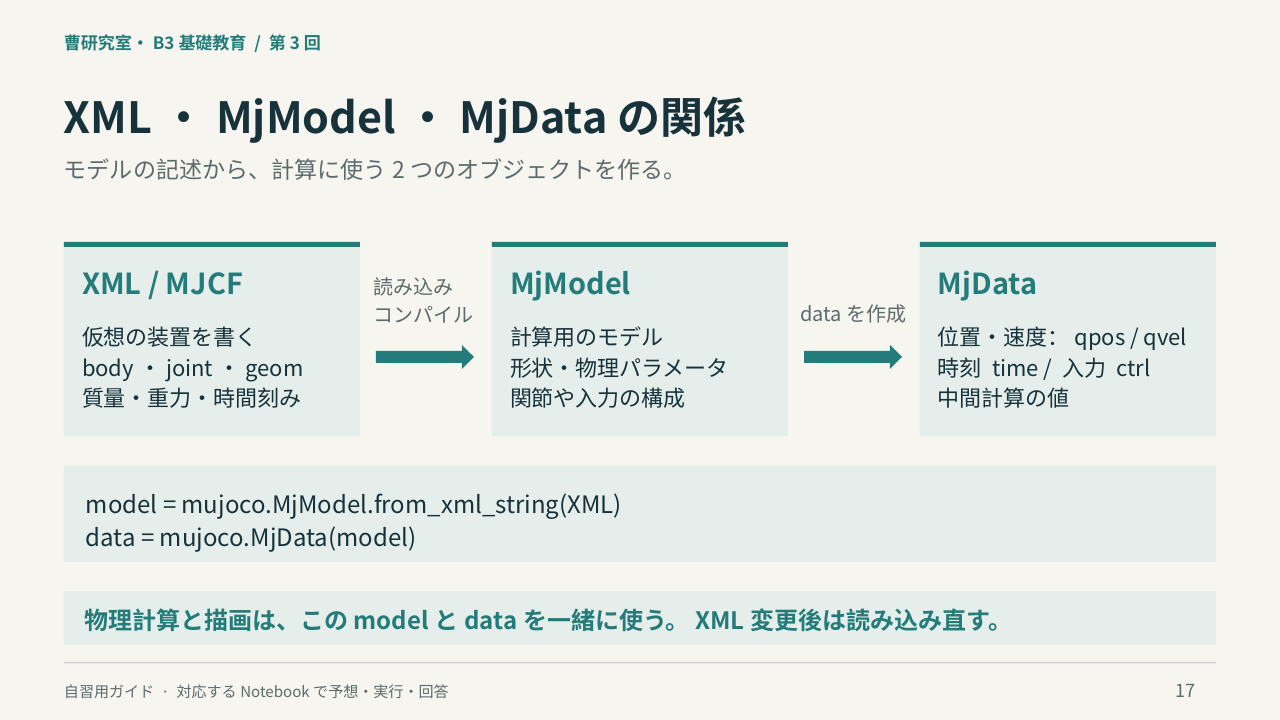

XMLは装置の説明、modelは読み込んだ計算用モデル、dataはそのモデルの現在の状態と計算用データです。図の役割を、この後の短いセルで一つずつ確認します。

### M1.2｜装置の説明を読む
`XML`はタグで構造を書く形式です。`<body> ... </body>`の中にあるものは、そのbodyに所属します。

|名前|この例での意味|
|---|---|
|`worldbody`|世界の基準。床や装置を置く場所|
|`body`|一緒に動く剛体のまとまり。`pos`は親から見た初期位置|
|`geom`|形・接触形状。この例は球で、質量もここに指定|
|`option`|重力と1ステップの時間などの計算条件|

`pos="0 0 1"`はx=0、y=0、z=1 mです。`size="0.05"`はこの球の半径です。
**まだjoint（関節）を入れていません。** 「質量1 kg、重力ありなら落ちる」と予想しますか。

In [20]:
FIXED_XML = """<mujoco>
  <option timestep="0.002" gravity="0 0 -9.81" integrator="Euler"/>
  <worldbody>
    <body name="ball" pos="0 0 1">
      <geom name="ball_geom" type="sphere" size="0.05" mass="1"/>
    </body>
  </worldbody>
</mujoco>"""
fixed_model = mujoco.MjModel.from_xml_string(FIXED_XML)
fixed_data = mujoco.MjData(fixed_model)

### M1.3｜モデルと現在の状態を別にする
`MjModel.from_xml_string(...)`がXMLを読み、計算用モデルを作ります。`MjData(model)`は、そのモデル用の状態・計算データを作ります。

`mj_forward`は現在の関節座標から物体の位置などを更新します。**時刻を進めません。** `mj_step`は動力学を計算して時刻・状態を1ステップ進めます。
下の例では、描画なしでも時刻と球の位置を確認できます。
`fixed_data.geom("ball_geom")`は、名前で球のgeomのデータを取り出します。続く`.xpos`はその世界位置、`[2]`はzです。`copy()`は今の値のコピーです。

**実行前の予想（時刻と高さ）：**（記入）

In [21]:
mujoco.mj_forward(fixed_model, fixed_data)
print("前:", fixed_data.time, fixed_data.geom("ball_geom").xpos.copy())
for _ in range(100):
    mujoco.mj_step(fixed_model, fixed_data)
mujoco.mj_forward(fixed_model, fixed_data)
print("後:", fixed_data.time, fixed_data.geom("ball_geom").xpos.copy())
print("動ける自由度 nv =", fixed_model.nv)

前: 0.0 [0. 0. 1.]
後: 0.20000000000000015 [0. 0. 1.]
動ける自由度 nv = 0


### 記録 M1｜自分の言葉で説明
球が落ちなかった原因は「時間が進んでいない」でしょうか。「動ける構造になっていない」でしょうか。時刻と`nv`を根拠に説明してください。
jointがないbodyは**親に固定**されます。このbodyの親はworldです。親が動く別のモデルまで「jointなしなら世界で静止」と言えるでしょうか。
XMLの`mass`を変えただけで既存の`fixed_model`も変わりますか。XML→model→dataのどこを実行し直すか書いてください。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## M2｜動ける方向を作り、時間を進める
**到達点：** 関節座標と世界座標を区別し、短いstepループを自分で書く。

### M2.1｜まずslideの例を読む
`<joint type="slide" axis="0 0 1"/>`は、親に対するz方向の並進を1つ許します。回転は許しません。
以下は挿入箇所を示す小さな例です。文字列`replace`は該当文字を置き換えます。置き換えただけではシミュレータはまだ読み直しません。

In [22]:
slide_line = '<joint name="vertical" type="slide" axis="0 0 1" damping="0"/>'
SLIDE_XML = FIXED_XML.replace('<geom name="ball_geom"', slide_line + '\n<geom name="ball_geom"')
ball_model = mujoco.MjModel.from_xml_string(SLIDE_XML)
ball_data = mujoco.MjData(ball_model)
mujoco.mj_forward(ball_model, ball_data)
print("nq, nv =", ball_model.nq, ball_model.nv)
print("qpos =", ball_data.qpos, "世界の球の高さ =", ball_data.geom("ball_geom").xpos[2])

nq, nv = 1 1
qpos = [0.] 世界の球の高さ = 1.0


### M2.2｜qposはいつも世界の高さではない
このモデルのbodyは最初から1 mの高さにあります。`qpos[0]`は、その位置からのslideの変位です。
$$z_{\mathrm{world}}=1+q,\qquad \dot z_{\mathrm{world}}=\dot q.$$

|データ|このモデルでの意味|初期値|
|---|---|---|
|`data.qpos[0]`|slideの変位 [m]|0|
|`data.qvel[0]`|slideの速度 [m/s]|0|
|`data.geom("ball_geom").xpos[2]`|世界座標の球中心の高さ [m]|1|
|`data.time`|シミュレーションの時刻 [s]|0|

`model.nq`はqposの要素数、`model.nv`はqvelの要素数です。今のslideではどちらも1です。M4で複数種類の関節を比べます。

`qpos`を変更したら`mj_forward`で派生位置を更新してから読みます。次は姿勢を指定する操作で、落下を計算していません。

In [23]:
pose_data = mujoco.MjData(ball_model)
pose_data.qpos[0] = 0.20
mujoco.mj_forward(ball_model, pose_data)
print("変位 =", pose_data.qpos[0], "高さ =", pose_data.geom("ball_geom").xpos[2])
print("時刻 =", pose_data.time, "速度 =", pose_data.qvel[0])

変位 = 0.2 高さ = 1.2
時刻 = 0.0 速度 = 0.0


### M2.3｜一歩の例 → 自分で繰り返す
新しいdataから開始すれば、前の実験の速度や時刻が残りません。次の一歩を確認してから、課題の関数を書いてください。

In [24]:
one_data = mujoco.MjData(ball_model)
mujoco.mj_step(ball_model, one_data)
mujoco.mj_forward(ball_model, one_data)
print("一歩:", one_data.time, one_data.qpos.copy(), one_data.qvel.copy())
print("世界の高さ:", one_data.geom("ball_geom").xpos[2])

一歩: 0.002 [-3.924e-05] [-0.01962]
世界の高さ: 0.99996076


**プログラミング課題M2：** `pass`を「1ステップ進める行」に置き換えます。引数`model`と`data`を使ってください。関数の定義、呼び出し、戻り値を第1・2回の教材で確認しても構いません。

**関数の約束：** 入力はmodel、現在のdata、繰り返す回数stepsです。data自体が更新され、同じdataを戻り値として返します。`pass`は何もしない仮置きです。
`steps=100`なら何秒進みますか。最初に計算してから実行します。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [25]:
def advance(model, data, steps):
    for _ in range(steps):
        pass  # TODO: modelとdataを使って1ステップ進める
    return data

In [26]:
#@title 課題の確認道具（実装を補いません）
def check_advance(fn, verbose=True):
    try:
        d = mujoco.MjData(ball_model)
        out = fn(ball_model, d, 100)
        if verbose: print("実測 time / qpos / qvel:", d.time, d.qpos.copy(), d.qvel.copy())
        ok = (out is d and abs(d.time - .2) < 1e-10
              and np.allclose(d.qpos, [-.198162]) and np.allclose(d.qvel, [-1.962]))
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("M2 コード確認:", "PASS" if ok else "未完成／再確認（時刻・位置・速度を確認）")
    return bool(ok)
advance_ready = check_advance(advance)
if advance_ready:
    fall_data = advance(ball_model, mujoco.MjData(ball_model), 100)
    mujoco.mj_forward(ball_model, fall_data)
    print("時刻・高さ・速度:", fall_data.time, fall_data.geom("ball_geom").xpos[2], fall_data.qvel[0])

実測 time / qpos / qvel: 0.0 [0.] [0.]
M2 コード確認: 未完成／再確認（時刻・位置・速度を確認）


### M2.4｜MuJoCoのEulerは、先ほどの式と同じ？
このXMLは`integrator="Euler"`、関節の減衰0、接触なしです。この条件では、MuJoCoのEulerは速度を先に更新する半陰的Eulerです。

|方法|一歩の更新順序|
|---|---|
|手書きの顕式Euler|$z_{n+1}=z_n+\Delta t\,v_n$、$v_{n+1}=v_n-g\Delta t$|
|このMuJoCoのEuler|$v_{n+1}=v_n-g\Delta t$、$z_{n+1}=z_n+\Delta t\,v_{n+1}$|

MuJoCoはEuler・RK4・implicit・implicitfastを備えています。Eulerには関節減衰の陰的処理もあります。接触力を求める処理と、時間積分法は別の役割です。
**同じ刻みでも結果が一致するとは限りません。** 一定重力だけでRK4が解析解と一致したことを、接触やどの物理モデルにも広げないでください。

### 記録 M2｜自分の言葉で説明
`qpos=0.20`なのに高さが0.20 mでなかったのはなぜですか。
`mj_forward`だけを100回呼んだ場合と`mj_step`を100回呼んだ場合の時刻の違いを説明してください。
自分で完成させた`advance`の時刻・高さ・速度を記録し、手書きEulerと位置更新の順序を比較してください。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## M3｜床を追加し、接触を数値で確認する
**到達点：** モデルへの追加・時間の記録・動画の役割を区別する。

### M3.1｜床のXMLを自分で足す
床はworldに固定した`geom`です。bodyの中に入れると、そのbodyと一緒に動いてしまいます。

例：`<geom name="floor" type="plane" size="2 2 0.1"/>`

**課題M3：** 下の空文字列に床の1行を書いてください。`worldbody`の直後に挿入してモデルを作り直します。
このplaneはz=0の平面です。planeの`size`は表示などに使われ、ここで有限の厚い床を作る指定ではありません。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [27]:
floor_line = ""  # TODO: 上の例を参考に、床のgeomを書く
CONTACT_XML = SLIDE_XML.replace("<worldbody>", "<worldbody>\n" + floor_line)
contact_model = mujoco.MjModel.from_xml_string(CONTACT_XML)
print("geom数 =", contact_model.ngeom)

geom数 = 1


### M3.2｜記録の一行を読む
まず`rows.append`に、その時点の時刻・球中心の高さ・速度の3つを入れます。

下の例は100回進め、**初期状態を含む101行**を記録します。更新前を記録して、最後の行の後には進めません。

In [28]:
log_data = mujoco.MjData(ball_model)
rows = []
for i in range(101):
    mujoco.mj_forward(ball_model, log_data)
    rows.append([log_data.time, log_data.geom("ball_geom").xpos[2], log_data.qvel[0]])
    if i < 100:
        mujoco.mj_step(ball_model, log_data)
freefall_table = pd.DataFrame(rows, columns=["time_s", "height_m", "velocity_mps"])
display(freefall_table.iloc[[0, -1]])

,time_s,height_m,velocity_mps
0,0.0,1.000000,0.000
100,0.2,0.801838,-1.962


### M3.3｜同じ記録を1.2秒まで続ける
下の道具`record_ball(model)`は今のループを長くしたものです。
**入力：** z向きslide・初期body高さ1 mの球モデル。**出力：** 表と再生用qpos配列。
3列の例に`d.ncon`（接触の個数）を追加します。`d.qpos.copy()`は、その時点の関節座標を別の配列として保存します。
必ず新しいdataで始めます。動画より先に、表の高さ・速度・接触数を確認してください。

In [29]:
#@title 小球の記録ツール（M3.2のループを関数にまとめたもの）
def record_ball(model, duration=1.2):
    d = mujoco.MjData(model)
    steps = round(duration/model.opt.timestep)
    rows, positions = [], []
    for i in range(steps + 1):
        mujoco.mj_forward(model, d)
        rows.append([d.time, d.geom("ball_geom").xpos[2], d.qvel[0], d.ncon])
        positions.append(d.qpos.copy())
        if i < steps: mujoco.mj_step(model, d)
    return pd.DataFrame(rows, columns=["time_s","height_m","velocity_mps","contacts"]), np.array(positions)

def check_floor(xml, verbose=True):
    try:
        m = mujoco.MjModel.from_xml_string(xml)
        floor_id = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_GEOM, "floor")
        structural = (floor_id >= 0 and m.geom_bodyid[floor_id] == 0
                      and m.geom_type[floor_id] == mujoco.mjtGeom.mjGEOM_PLANE)
        table, _ = record_ball(m)
        ok = (structural and (table.contacts > 0).any()
              and abs(table.height_m.iloc[-1] - .05) < .005)
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("M3 コード確認:", "PASS" if ok else "未完成／再確認（world側の床を確認）")
    return bool(ok)

floor_ready = check_floor(CONTACT_XML)
contact_table, contact_qpos = record_ball(contact_model)
display(contact_table.iloc[[0, -1]])
contact_rows = contact_table[contact_table.contacts > 0]
display(contact_rows.head(2), contact_table.tail(3))
no_floor_table, _ = record_ball(ball_model)
display(pd.DataFrame([
    ["without floor", no_floor_table.height_m.iloc[-1], no_floor_table.velocity_mps.iloc[-1]],
    ["your floor XML", contact_table.height_m.iloc[-1], contact_table.velocity_mps.iloc[-1]]
], columns=["model", "height_at_1.2s_m", "velocity_at_1.2s_mps"]))
if not floor_ready:
    print("床が未完成の結果です。落ち続ける理由を確認して、M3を修正・再実行してください。")

M3 コード確認: 未完成／再確認（world側の床を確認）


,time_s,height_m,velocity_mps,contacts
0,0.0,1.000000,0.000,0
600,1.2,-6.074972,-11.772,0


,time_s,height_m,velocity_mps,contacts


,time_s,height_m,velocity_mps,contacts
598,1.196,-6.027923,-11.73276,0
599,1.198,-6.051428,-11.75238,0
600,1.200,-6.074972,-11.77200,0


,model,height_at_1.2s_m,velocity_at_1.2s_mps
0,without floor,-6.074972,-11.772
1,your floor XML,-6.074972,-11.772


床が未完成の結果です。落ち続ける理由を確認して、M3を修正・再実行してください。


### M3.4｜計算済みの記録をアニメーションにする
ここで初めて3D表示の道具を使います。`render_qpos_log`は、XMLと**計算済みのqpos列**を受け取り、PNGと動画HTMLを作ります。再生中に動力学を計算する道具ではありません。
Colabで表示できます。再生ボタンを押してください。床が未完成なら、先に修正してからこのセルまで再実行します。

In [30]:
#@title 3D表示の道具：計算済みqposを再生する
def render_qpos_log(xml, qpos_log, name, lookat, distance, elevation=-25, azimuth=90):
    m = mujoco.MjModel.from_xml_string(xml)
    m.vis.headlight.ambient[:] = [0.6, 0.6, 0.6]
    m.vis.headlight.diffuse[:] = [0.8, 0.8, 0.8]
    d = mujoco.MjData(m)
    camera = mujoco.MjvCamera()
    camera.lookat[:] = lookat
    camera.distance, camera.elevation, camera.azimuth = distance, elevation, azimuth
    indices = np.unique(np.linspace(0, len(qpos_log)-1, min(40, len(qpos_log))).astype(int))
    frames = []
    with mujoco.Renderer(m, height=320, width=480) as renderer:
        for i in indices:
            d.qpos[:] = np.asarray(qpos_log[i])
            mujoco.mj_forward(m, d)
            renderer.update_scene(d, camera=camera)
            frames.append(renderer.render().copy())
    plt.imsave(WORK / f'{name}_first.png', frames[0])
    plt.imsave(WORK / f'{name}_last.png', frames[-1])
    fig, ax = plt.subplots(figsize=(7.2, 4.8)); ax.axis('off')
    picture = ax.imshow(frames[0])
    def update(i):
        picture.set_data(frames[i]); return (picture,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=70, blit=True)
    content = animation.to_jshtml(default_mode='once'); plt.close(fig)
    (WORK / f'{name}.html').write_text(content, encoding='utf-8')
    return HTML(content)

In [31]:
if floor_ready:
    display(render_qpos_log(CONTACT_XML, contact_qpos, "ball_contact",
                           [0, 0, .45], 2.2))
else:
    print("M3の床を完成させると、接触の動画を表示できます。")

M3の床を完成させると、接触の動画を表示できます。


### 記録 M3｜自分の言葉で説明
最初に`contacts > 0`になった時点で、球はもう静止していますか。最初の接触時と末尾3行の高さ・速度・接触数を比べてください。
同じ初期状態・同じ1.2秒の無床／有床の表を比較し、「XMLのどこを変えたか→どの数値が変わったか→その理由」を説明してください。
球の半径は0.05 mです。接触後の中心高さが厳密に0.05 mでないことをどう考えますか。MuJoCoの接触は柔らかさを持つ近似なので、小さな侵入だけで直ちに実装ミスと判断しません。
動画が表示されなくても、計算が進んだと判断するにはどの記録を確認しますか。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## M4｜形が球ならball joint？ 関節は運動の制約
**到達点：** 形状と関節を分けて考え、要求に合う関節をXMLに書く。

### M4.1｜自由度は「独立に動ける方向の数」
ドアは1軸だけ回転し、引き出しは1方向だけ移動します。球の形の部品でも、固定・slide・hingeのどれも使えます。

|設定|親に対して許す運動|`nq`：座標の数|`nv`：速度の数＝自由度|
|---|---|---:|---:|
|jointなし|親に固定|0|0|
|`hinge`|指定した軸の回転|1|1|
|`slide`|指定した軸の並進|1|1|
|`ball`|3方向の回転。並進は許さない|4|3|
|`freejoint`|3並進＋3回転|7|6|

ball/freeの姿勢は4成分のクォータニオンで持つため、`nq`と自由度は一致しません。今回はクォータニオンの計算は実装せず、この違いを説明します。freejointはworld直下のbodyに使います。

### M4.2｜中心が固定でも先端の球は動く
観察用モデルは、body原点からx方向0.25 m離れた場所に球を持つ細い棒です。関節はbody原点にあります。
下の道具はこの同じ形状で関節を変えます。**入力：** 関節名。**出力：** modelと原点・球中心の世界座標の表。hingeの軸はyです。

In [32]:
#@title 関節の観察ツール（関節文字列 → 新しいmodel/data → step → 記録）
JOINT_XML = {
    "fixed": "",
    "hinge": '<joint type="hinge" axis="0 1 0" damping="0"/>',
    "slide": '<joint type="slide" axis="0 0 1" damping="0"/>',
    "ball": '<joint type="ball" damping="0"/>',
    "free": '<freejoint/>'
}
def observe_joint(kind, hinge_axis="0 1 0"):
    joint_xml = JOINT_XML[kind]
    if kind == "hinge":
        joint_xml = f'<joint type="hinge" axis="{hinge_axis}" damping="0"/>'
    xml = f'''<mujoco><option timestep="0.002" gravity="0 0 -9.81"/>
      <worldbody><body name="object" pos="0 0 1">{joint_xml}
        <geom type="capsule" fromto="0 0 0 0.25 0 0" size="0.008" mass="0.01"/>
        <geom name="tip" type="sphere" pos="0.25 0 0" size="0.035" mass="1"/>
      </body></worldbody></mujoco>'''
    m = mujoco.MjModel.from_xml_string(xml); d = mujoco.MjData(m)
    b = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, "object")
    tip = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_GEOM, "tip")
    rows = []
    for i in range(101):
        mujoco.mj_forward(m, d)
        rows.append([d.time, *d.xpos[b].copy(), *d.geom_xpos[tip].copy()])
        if i < 100: mujoco.mj_step(m, d)
    log = pd.DataFrame(rows, columns=["time_s", "origin_x", "origin_y", "origin_z", "tip_x", "tip_y", "tip_z"])
    return m, log
def show_joint_choice(kind, hinge_axis="0 1 0"):
    m, log = observe_joint(kind, hinge_axis)
    print("選んだ関節:", kind, " / nq =", m.nq, "/ 自由度 nv =", m.nv)
    display(log.iloc[[0, -1]])
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(log.tip_x, log.tip_z, label="Ball center path")
    ax.scatter(log.tip_x.iloc[0], log.tip_z.iloc[0], s=25, marker="o", label="Ball at start")
    ax.scatter(log.tip_x.iloc[-1], log.tip_z.iloc[-1], s=30, marker="s", label="Ball at 0.2 s")
    ax.scatter(log.origin_x.iloc[0], log.origin_z.iloc[0], marker="x", label="Initial body origin")
    ax.set(xlabel="x [m]", ylabel="z [m]", title=kind, xlim=(-.05,.35), ylim=(.7,1.05))
    ax.set_aspect("equal"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()
    return m, log

,joint,nq,nv,origin_z,tip_z
0,fixed,0,0,1.000000,1.000000
1,hinge,1,1,1.000000,0.825617
2,slide,1,1,0.801838,0.801838
3,ball,4,3,1.000000,0.825617
4,free,7,6,0.801838,0.801838


選んだ関節: hinge  / nq = 1 / 自由度 nv = 1


,time_s,origin_x,origin_y,origin_z,tip_x,tip_y,tip_z
0,0.0,0.0,0.0,1.0,0.250000,0.0,1.000000
100,0.2,0.0,0.0,1.0,0.179138,0.0,0.825617


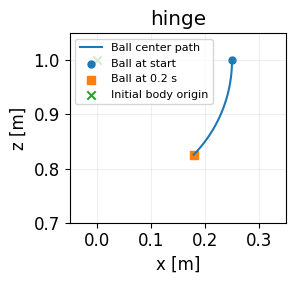

In [33]:
joint_dimensions = []
for kind in ["fixed", "hinge", "slide", "ball", "free"]:
    jm, jl = observe_joint(kind)
    joint_dimensions.append([kind, jm.nq, jm.nv,
                             jl.origin_z.iloc[-1], jl.tip_z.iloc[-1]])
display(pd.DataFrame(joint_dimensions, columns=["joint", "nq", "nv", "origin_z", "tip_z"]))
show_joint_choice("hinge");

**必修確認：** 次の`hinge_axis`を`"0 0 1"`に変え、y軸の場合と球中心の軌道・自由度を比べます。観察用モデルは重りが原点から離れています。次のM4.3の課題モデルは、球中心がbody原点にある別の形状です。

**実行前の予想と理由：**（記入）

選んだ関節: hinge  / nq = 1 / 自由度 nv = 1


,time_s,origin_x,origin_y,origin_z,tip_x,tip_y,tip_z
0,0.0,0.0,0.0,1.0,0.250000,0.0,1.000000
100,0.2,0.0,0.0,1.0,0.179138,0.0,0.825617


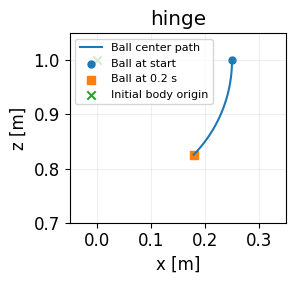

In [34]:
hinge_axis = "0 1 0"  # 次に "0 0 1" に変えて比較する
show_joint_choice("hinge", hinge_axis);

### M4.3｜要求からXMLを自分で直す
**課題M4：** 「球はz方向だけに動き、回転しない」装置を作ります。
下の`ball`関節を適切なタグに直してください。動く方向を指定する属性も書きます。`ball`は形状の名前から選ぶものではありません。

実行前に`nq`と`nv`を予想してください。次に0.2秒後の世界座標で確かめます。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [35]:
chosen_joint = '<joint name="chosen" type="ball"/>'
CHOSEN_XML = FIXED_XML.replace('<geom name="ball_geom"', chosen_joint + '\n<geom name="ball_geom"')
chosen_model = mujoco.MjModel.from_xml_string(CHOSEN_XML)
print("nq, nv =", chosen_model.nq, chosen_model.nv)

nq, nv = 4 3


In [36]:
#@title 関節課題の確認道具
def check_joint(xml, verbose=True):
    try:
        m = mujoco.MjModel.from_xml_string(xml)
        ok = (m.njnt == 1 and m.nv == 1
              and m.jnt_type[0] == mujoco.mjtJoint.mjJNT_SLIDE
              and np.allclose(np.abs(m.jnt_axis[0]), [0,0,1]))
        d = mujoco.MjData(m)
        for _ in range(100): mujoco.mj_step(m, d)
        mujoco.mj_forward(m, d)
        if verbose: print("世界の球中心:", d.geom("ball_geom").xpos.copy())
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("M4 コード確認:", "PASS" if ok else "未完成／再確認（種類と軸を確認）")
    return bool(ok)
joint_ready = check_joint(CHOSEN_XML)

世界の球中心: [0. 0. 1.]
M4 コード確認: 未完成／再確認（種類と軸を確認）


### 記録 M4｜自分の言葉で説明
「球だからball joint」とすると、落下モデルとして何が違いますか。
観察例ではhingeとballが似た軌道を描くことがあります。それだけで自由度が同じと言えるでしょうか。`nq,nv`と許される運動で説明してください。
hingeの軸をyからzに変え、重力で回転しなくなった場合、「回転できない」と結論してよいでしょうか。重力の軸まわりのモーメントも考えてください。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## M8｜Terminalで独立実行し、表示に頼らず診断する
**到達点：** Notebookと独立したPythonプログラムを実行し、CSVを根拠に結果を調べる。

### M8.1｜ファイルとプロセスを分ける
第2回で使った`pwd`（現在地）・`ls`（一覧）・`head`（先頭を読む）を再利用します。
これから用意する`run_ball.py`は、`ball.xml`を読み、落下を計算して`terminal_ball.csv`に保存します。Notebookの`ball_model`などの変数は別プロセスに自動では渡りません。

M3の床が未完成でも実行方法を学べるよう、床付きの**配布用XML**を別ファイルに保存します。M3の課題を完成扱いにはしません。
このセルから必要なファイルを自動で作るので、学生がNotebookをコピーした後に個別のファイルをアップロードする必要はありません。

In [37]:
#@title 独立実行のためのXMLとPythonファイルを準備
TERMINAL_XML = SLIDE_XML.replace("<worldbody>", '<worldbody><geom name="floor" type="plane" size="2 2 0.1"/>')
(WORK/"ball.xml").write_text(TERMINAL_XML, encoding="utf-8")
script = """from pathlib import Path
import sys, csv, mujoco
folder = Path(__file__).resolve().parent
model = mujoco.MjModel.from_xml_path(str(folder/"ball.xml"))
data = mujoco.MjData(model)
initial_height = float(sys.argv[1]) if len(sys.argv) > 1 else 1.0
data.qpos[0] = initial_height - 1.0
with (folder/"terminal_ball.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["time_s", "height_m", "velocity_mps", "contacts"])
    for i in range(601):
        mujoco.mj_forward(model, data)
        writer.writerow([data.time, data.geom("ball_geom").xpos[2], data.qvel[0], data.ncon])
        if i < 600:
            mujoco.mj_step(model, data)
print("saved:", folder/"terminal_ball.csv")
"""
(WORK/"run_ball.py").write_text(script, encoding="utf-8")
print(script)
print("作業フォルダ:", WORK)

from pathlib import Path
import sys, csv, mujoco
folder = Path(__file__).resolve().parent
model = mujoco.MjModel.from_xml_path(str(folder/"ball.xml"))
data = mujoco.MjData(model)
initial_height = float(sys.argv[1]) if len(sys.argv) > 1 else 1.0
data.qpos[0] = initial_height - 1.0
with (folder/"terminal_ball.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["time_s", "height_m", "velocity_mps", "contacts"])
    for i in range(601):
        mujoco.mj_forward(model, data)
        writer.writerow([data.time, data.geom("ball_geom").xpos[2], data.qvel[0], data.ncon])
        if i < 600:
            mujoco.mj_step(model, data)
print("saved:", folder/"terminal_ball.csv")

作業フォルダ: /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/ball-student/b3_lesson03A_ball


### M8.2｜コマンドを一つずつ読む
`python run_ball.py 1.5`の`1.5`は文字列の引数です。`sys.argv[1]`で受け取り、`float`で数値にします。これは初期の**世界高さ**なので、slideの変位には`1.5 - 1.0`を代入します。

Pythonファイルは通常`python ファイル名`で実行します。C言語のように別途コンパイルコマンドを打つ手順は今回ありません。

**必修操作：** 下に表示するコマンドを1行ずつ実行し、高さ1.0と1.5 mを比べてください。ColabのTerminalが利用できる場合はそこで実行します。利用できない場合も、次のNotebookセルから同じ外部プロセスを実行できます。両方とも同じXML・Pythonファイルを使います。

`tail -n 3`は末尾3行、`wc -l`は行数です。CSVは見出しが1行あるので、測定行数とは1行違います。`cp 元 保存先`で実験ごとにコピーを残します。

**必修プログラミング課題M8：** 表示された`run_ball.py`を読み、CSVの最後に`displacement_m`列を追加してください。`writer.writerow`の見出しの行と、数値を書き込む行の両方を直します。値はM2で学んだslideの変位です。上の道具の`script`文字列を編集して再実行するか、Colabのファイル欄で`run_ball.py`を編集できます。
追加後、2つの初期高さで実行し、`height_m - displacement_m`がどうなるか説明してください。翌週のPPT発表では、追加したコードとCSVの数行を示し、この差が何を表すか説明してください。

In [38]:
import shlex
print("cd " + shlex.quote(str(WORK)))
print("pwd")
print("ls")
print(shlex.quote(sys.executable) + " run_ball.py 1.0")
print("head -n 4 terminal_ball.csv")
print("tail -n 3 terminal_ball.csv")
print("wc -l terminal_ball.csv")
print("cp terminal_ball.csv terminal_ball_1m.csv")
print(shlex.quote(sys.executable) + " run_ball.py 1.5")
print("head -n 4 terminal_ball.csv")
print("cp terminal_ball.csv terminal_ball_1p5m.csv")

cd '/home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/ball-student/b3_lesson03A_ball'
pwd
ls
'/home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/15回教材_20260923/.build/venv/bin/python' run_ball.py 1.0
head -n 4 terminal_ball.csv
tail -n 3 terminal_ball.csv
wc -l terminal_ball.csv
cp terminal_ball.csv terminal_ball_1m.csv
'/home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/15回教材_20260923/.build/venv/bin/python' run_ball.py 1.5
head -n 4 terminal_ball.csv
cp terminal_ball.csv terminal_ball_1p5m.csv


In [39]:
# Notebookからも、同じ外部Pythonプロセスを実行できる
for initial_height, suffix in [(1.0,"1m"), (1.5,"1p5m")]:
    result = subprocess.run([sys.executable, str(WORK/"run_ball.py"), str(initial_height)],
                            check=True, capture_output=True, text=True)
    print(result.stdout)
    terminal_table = pd.read_csv(WORK/"terminal_ball.csv")
    terminal_table.to_csv(WORK/f"terminal_ball_{suffix}.csv", index=False)
    display(terminal_table.head(1), terminal_table.tail(1))
print("M8の列追加:", "列あり・値と説明を確認" if "displacement_m" in terminal_table else "未完成：displacement_m列を追加")

saved: /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/ball-student/b3_lesson03A_ball/terminal_ball.csv



,time_s,height_m,velocity_mps,contacts
0,0.0,1.0,0.0,0


,time_s,height_m,velocity_mps,contacts
600,1.2,0.049633,7.277974e-15,1


saved: /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/ball-student/b3_lesson03A_ball/terminal_ball.csv



,time_s,height_m,velocity_mps,contacts
0,0.0,1.5,0.0,0


,time_s,height_m,velocity_mps,contacts
600,1.2,0.049633,-6.325977e-15,1


M8の列追加: 未完成：displacement_m列を追加


### 記録 M8｜自分の言葉で説明
初期高さ1.0と1.5 mの実行について、最初の高さ・最後の時刻・行数を記録してください。
動画がなくても計算が動いた根拠は何ですか。ファイルの存在だけで今回の結果と判断せず、初期値も確認してください。
`No such file or directory`が出た場合、最初にどのコマンドで何を調べますか。
Notebookの変数を変更しても独立した`run_ball.py`の条件が変わらない場合、どのファイルまたは引数を確認しますか。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## T｜必修の転移課題：横向き運動・誤差・抵抗
**到達点：** 完成したEuler/RK4を別の状態に使い、数値誤差とモデルの違いを分ける。

### T.1｜高さだけから、x-zの運動へ
状態を$\boldsymbol{s}=[x,v_x,z,v_z]^T$に増やします。床に当たる前、重力だけなら変化率は次の通りです。
$$\dot{\boldsymbol{s}}=[v_x,0,v_z,-g]^T.$$
第4節の`euler_step`と自作`rk4_step`は、変化率の関数を渡せば4成分でも使えます。

In [40]:
def flight_rate(state):
    x, vx, z, vz = state
    return np.array([vx, 0., vz, -g])

def simulate_flight(step, rate, vx, dt):
    steps = round(.4/dt)
    state = np.array([0., vx, 1., 0.])
    rows = [[0., *state]]
    for i in range(steps):
        state = step(rate, state, dt)
        rows.append([(i+1)*dt, *state])
    return pd.DataFrame(rows, columns=["time_s","x_m","vx_mps","z_m","vz_mps"])

**課題T1：** **最初に地面へ着いた位置**のxを1.7〜1.9 mにし、**0.40秒時点**の解析解に対する高さ誤差を0.005 m以下にします。
解析解は$x=v_{x0}t$、$z=1-\tfrac12gt^2$です。着地時刻は$z=0$を解いて求められます。`flight_vx`、積分法、刻みを選び、理由と少なくとも2回の結果を書きます。
計算時間を揃えるため、0.40秒を整数回で割れる刻みにします（例：0.05、0.01、0.002）。RK4を選ぶには第4節の実装が必要です。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [41]:
flight_vx = 1.0
flight_method = "Euler"  # "Euler" または "RK4"
flight_dt = .05

### T.1の着地判定｜指定した時刻で止めることとは違う
ここは半径を無視した質点モデルです。MuJoCoの半径0.05 mの球とは接触高さが違います。
下の道具は初めて$z\leq0$になったステップを探し、前後の2点の間を直線で補間して着地時刻・位置を推定します。補間も近似なので、刻みによるずれが残ります。
**入力：** 積分法・初速度・刻み。**出力：** 着地までの表。最後のzは0で、0.40秒の誤差表とは別の記録です。

In [42]:
#@title 転移課題の実行と確認
def flight_to_landing(step, vx, dt):
    state = np.array([0., vx, 1., 0.]); time_s = 0.
    rows = [[time_s, *state]]
    for _ in range(int(np.ceil(2./dt))):
        next_state = step(flight_rate, state, dt)
        if next_state[2] <= 0.:
            fraction = state[2] / (state[2] - next_state[2])
            landing = state + fraction*(next_state - state)
            landing[2] = 0.
            rows.append([time_s + fraction*dt, *landing])
            break
        time_s += dt; state = next_state
        rows.append([time_s, *state])
    else:
        raise ValueError("2秒以内に着地を検出できません")
    return pd.DataFrame(rows, columns=["time_s","x_m","vx_mps","z_m","vz_mps"])

def evaluate_transfer(vx, method, dt, verbose=True):
    try:
        if not (np.isfinite([vx,dt]).all() and .0001 <= dt <= .4 and abs(round(.4/dt)*dt-.4) < 1e-10):
            raise ValueError("dtは0.40秒を整数回で割れる0.0001〜0.4の値にします")
        if method not in ["Euler", "RK4"]: raise ValueError("積分法の名前を確認します")
        if method == "RK4" and not check_rk4(rk4_step, verbose=False):
            raise ValueError("先にRK4を完成させます")
        step = euler_step if method == "Euler" else rk4_step
        before_contact = simulate_flight(step, flight_rate, vx, dt)
        error = abs(before_contact.z_m.iloc[-1] - (1-.5*g*.4**2))
        table = flight_to_landing(step, vx, dt)
        passed = bool(1.7 <= table.x_m.iloc[-1] <= 1.9 and error <= .005)
        if verbose:
            print("着地時刻 [s]:", table.time_s.iloc[-1], "着地x [m]:", table.x_m.iloc[-1])
            print("0.40秒の高さ誤差 [m]:", error, "目標達成:", passed)
        return passed, table
    except Exception as e:
        if verbose: print("未完成／再確認:", str(e))
        return False, None
transfer_ready, flight_table = evaluate_transfer(flight_vx, flight_method, flight_dt)
if flight_table is not None:
    display(flight_table.iloc[[0, -1]])
    frame_indices = np.unique(np.linspace(0, len(flight_table)-1, min(60,len(flight_table))).astype(int))
    display(ball_animation(flight_table.iloc[frame_indices], "horizontal_flight", target=(1.7,1.9)))

着地時刻 [s]: 0.47652622041001236 着地x [m]: 0.47652622041001236
0.40秒の高さ誤差 [m]: 0.09809999999999997 目標達成: False


,time_s,x_m,vx_mps,z_m,vz_mps
0,0.000000,0.000000,1.0,1.0,0.000000
10,0.476526,0.476526,1.0,0.0,-4.674722


### T.2｜抵抗を足すと、同じ公式のままでよい？
ここでは速さに比例する簡単な空気抵抗を仮定します。質量$m=1$ kg、係数$c=1$ kg/sです。実物の全条件でこの抵抗式が成り立つという意味ではありません。
$$\dot{\boldsymbol{s}}=
\begin{bmatrix}
v_x\\-cv_x/m\\v_z\\-g-cv_z/m
\end{bmatrix}.$$

**課題T2：** 式を4成分の`np.array`に対応させて`drag_rate`を書きます。下向き速度$v_z<0$のとき、抵抗のz成分は上向きになることを確認してください。

**実行前の予想と理由：**（ここに記入してから、下の課題を実行）

In [43]:
mass_drag, drag_c = 1.0, 1.0
def drag_rate(state):
    x, vx, z, vz = state
    return None  # TODO: 4成分の変化率を返す

In [44]:
#@title 抵抗の式の確認と比較
def check_drag(fn, verbose=True):
    try:
        ok = True
        for vx, vz in [(4.,-1.5), (-2.,3.), (0.,0.)]:
            s = np.array([0.,vx,1.,vz]); before = s.copy()
            value = fn(s)
            expected = [vx, -drag_c*vx/mass_drag, vz, -g-drag_c*vz/mass_drag]
            ok = (ok and value is not None and np.asarray(value).shape == (4,)
                  and np.allclose(value, expected) and np.array_equal(s, before))
    except Exception as e:
        ok = False
        if verbose: print(type(e).__name__, str(e)[:160])
    if verbose: print("T2 コード確認:", "PASS" if ok else "未完成／再確認（抵抗の符号・質量を確認）")
    return bool(ok)
drag_ready = check_drag(drag_rate)
drag_table = None
if drag_ready and check_rk4(rk4_step, verbose=False):
    no_drag = simulate_flight(rk4_step, flight_rate, 4.5, .01)
    drag_table = simulate_flight(rk4_step, drag_rate, 4.5, .01)
    drag_euler = simulate_flight(euler_step, drag_rate, 4.5, .01)
    fig, ax = plt.subplots()
    ax.plot(no_drag.x_m, no_drag.z_m, label="No drag")
    ax.plot(drag_table.x_m, drag_table.z_m, label="Linear drag")
    ax.plot(drag_euler.x_m, drag_euler.z_m, "--", label="Linear drag / Euler")
    ax.set(xlabel="x [m]", ylabel="z [m]"); ax.legend()
    fig.savefig(WORK/"drag_compare.png"); plt.show()
    display(drag_table.iloc[[0,-1]], drag_euler.iloc[[0,-1]])
else:
    print("RK4とT2の完成後に抵抗あり・なしを比較します。")

T2 コード確認: 未完成／再確認（抵抗の符号・質量を確認）
RK4とT2の完成後に抵抗あり・なしを比較します。


### 記録 T｜自分の言葉で説明
T1で試した条件を2組以上、方法・刻み・0.40秒までの計算回数・着地時刻・着地x・0.40秒の高さ誤差とともに記録してください。0.40秒での終了と着地イベントでの終了は、同じ意味でしょうか。
T2の抵抗ありの結果を、抵抗なしの解析解と比べた差は、すべて数値積分誤差でしょうか。**物理モデルの変更による差**と区別して説明してください。
抵抗あり同士でEulerとRK4を比べる場合、何を揃えていますか。0.40秒の高さの差を示してください。
RK4が一定重力の落球で解析解と一致したことだけで、どんな運動でも正確だと言えますか。

- **予想：**（実行前に記入）
- **読んだコードと自分の変更：**（該当行と意味）
- **実際の数値・図：**（単位も記入）
- **根拠と説明：**（予想と違った場合、その理由・次に確認すること）

実行できたことと、説明できたことを分けて確認します。

## 小球篇の課題｜翌週のPPT発表を準備する
問い1・2、記録M1〜M4・M8・Tの回答と自作コードを使って、次の点を説明します。

- **積分法：** 同じ初期条件・同じ時刻でEuler／RK4／解析解をどう比較したか。刻み幅を変えたとき、誤差はどうなったか。
- **MuJoCo：** 小球をz方向だけに動かす関節と床はどこで設定するか。`mj_step`は何を更新し、`qpos`と球の高さはどう違うか。
- **自作・確認：** TerminalのCSV列追加や横向き運動・抵抗の課題で、どの行を変更し、どの数値で正しさを確かめたか。

**到達位置：** ＿＿　**残っている課題：** ＿＿

### 翌週のPPT発表の組み立て
課題の報告は**翌週の授業でのPPT発表**です。担当者が指定した範囲について、Notebookの回答を発表にまとめます。**ZIP・CSV・Notebookの提出は不要です。**

**PPTは全体で4〜5枚が目安。** 小球篇とロボット篇の両方を発表する場合も、1つの発表にまとめます。

1. **何を確かめたか：** 装置の図、実験条件、実行前の予想。
2. **どのように実装したか：** 自分で書いた重要な3〜8行と、その行の役割。ロボット篇では流れ図の場所も示す。
3. **何が起きたか：** 比較する図・表・短い動画。軸・単位・条件を付け、数値を1つ以上示す。
4. **なぜそうなったか：** 予想との一致・違い、その理由。上の確認質問にも答える。
5. **まだ分からないこと：** 必要なら1枚追加。試した変更、失敗、次に確認すること。

全課題に取り組み、回答は自分のNotebookに残します。発表では各セルを読み上げず、重要な比較と自作コードを使って説明します。未完成の課題も、どこまでできたか・何を試したか・どこで困ったかを示します。

**質疑で確認すること：** 「なぜこの行が必要？」「どの数値が説明の根拠？」「条件を変えるとどうなる？」。AIに相談したコードも、自分の言葉で説明してください。コードのPASSは理解度の採点ではありません。

### 自分用の記録を残す
回答と実行結果を含むNotebookを自分のGoogle Driveへ保存し、発表に使う図・表・コードをPPTへ貼り付けます。下のセルは自己確認と一時ファイルの保存用です。ZIPは作りません。Colabの実行環境内にあるCSV・XMLはDriveのNotebookに自動添付されないため、再実験で必要なものだけファイル欄から自分用に保存してください。

In [45]:
#@title 発表前の自己確認と実験記録（小球篇）
rk4_ready = check_rk4(rk4_step, verbose=False)
current_source = (rk4_step, ball_rate, euler_step, simulate, float(g))
comparison_saved = (rk4_ready and method_comparison is not None
    and comparison_source == current_source and (WORK/'euler_rk4_analytical.png').exists())
if comparison_saved:
    method_comparison.to_csv(WORK/'euler_rk4.csv', index=False)
else:
    (WORK/'euler_rk4.csv').unlink(missing_ok=True)
    (WORK/'euler_rk4_analytical.png').unlink(missing_ok=True)
    method_comparison, numerical_logs, comparison_source = None, None, None
statuses = {
    "RK4": bool(rk4_ready), "M2_advance": check_advance(advance, verbose=False),
    "M3_floor": check_floor(CONTACT_XML, verbose=False),
    "M4_joint": check_joint(CHOSEN_XML, verbose=False),
    "T2_drag": check_drag(drag_rate, verbose=False)}
statuses["T1_transfer"], fresh_flight = evaluate_transfer(flight_vx, flight_method, flight_dt, verbose=False)
for name in ['flight.csv', 'drag.csv']:
    (WORK/name).unlink(missing_ok=True)
euler_log.to_csv(WORK/'euler_ball.csv', index=False)
fresh_contact, _ = record_ball(mujoco.MjModel.from_xml_string(CONTACT_XML))
fresh_contact.to_csv(WORK/'contact_current.csv', index=False)
if fresh_flight is not None: fresh_flight.to_csv(WORK/'flight.csv', index=False)
if statuses['RK4'] and statuses['T2_drag']:
    simulate_flight(rk4_step, drag_rate, 4.5, .01).to_csv(WORK/'drag.csv', index=False)
for filename, xml in [('student_contact.xml', CONTACT_XML), ('student_joint.xml', CHOSEN_XML)]:
    (WORK/filename).write_text(xml, encoding='utf-8')
for valid,prefix in [(statuses['M3_floor'],'ball_contact'),(statuses['T2_drag'] and statuses['RK4'],'drag_compare')]:
    if not valid:
        for path in WORK.glob(prefix+'*'):
            if path.suffix in ['.png','.html']:path.unlink()
environment = {'lesson':'03A-ball-v10-split','python':sys.version.split()[0],
    'mujoco':mujoco.__version__,'colab':IN_COLAB,'rendering':os.environ.get('MUJOCO_GL'),
    'code_checks':statuses,'rk4_comparison_saved':bool(comparison_saved),
    'written_answers':'NOT_AUTO_GRADED: questions 1-2, M1-M4, M8, T',
    'terminal_evidence':'Check both initial heights and the added CSV column manually',
    'figures':'Snapshots: rerun display cells after changing conditions'}
(WORK/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
print('小球篇のコード確認:',statuses)
print('実験記録の一時フォルダ:',WORK)
print('課題は翌週のPPT発表で説明します。ZIPの提出は不要です。')
print('回答と実行結果入りNotebookを自分のDriveへ保存し、発表に使う図・表・コードをPPTへ貼り付けてください。')
print('このフォルダのCSV・XMLは実行環境内の一時ファイルです。必要なものはファイル欄から自分用に保存してください。')

小球篇のコード確認: {'RK4': False, 'M2_advance': False, 'M3_floor': False, 'M4_joint': False, 'T2_drag': False, 'T1_transfer': False}
実験記録の一時フォルダ: /home/jason/文档/研究室运营/B3_倒立摆翻转学习_2026秋/第3回_MuJoCo基礎から_20260930/v10_图解渐进_20261013/validation/split-run-20261013T080423Z-8kiuyali/ball-student/b3_lesson03A_ball
課題は翌週のPPT発表で説明します。ZIPの提出は不要です。
回答と実行結果入りNotebookを自分のDriveへ保存し、発表に使う図・表・コードをPPTへ貼り付けてください。
このフォルダのCSV・XMLは実行環境内の一時ファイルです。必要なものはファイル欄から自分用に保存してください。


## 参照資料
用語と動作は配布環境のMuJoCo 3.3.3で確認します。

- [MuJoCo Overview：モデル・データ・動力学](https://mujoco.readthedocs.io/en/3.3.3/overview.html)
- [Modeling：親子構造と座標](https://mujoco.readthedocs.io/en/3.3.3/modeling.html#kinematic-tree)
- [XML reference：joint](https://mujoco.readthedocs.io/en/3.3.3/XMLreference.html#body-joint)
- [Simulation：forwardとstep](https://mujoco.readthedocs.io/en/3.3.3/programming/simulation.html)
- [Computation：積分・接触・入力](https://mujoco.readthedocs.io/en/3.3.3/computation/index.html)

導入の出典付き画像は前版から保持しています。数値図・動画はこのNotebookの計算結果です。